# Explainable Early Mortality Risk Prediction in Sepsis Patients Using Clinical and Temporal Features
## Healthcare Analytics Mini Project — Google Colab




## 1. Setup and project configuration
Run the cells from top to bottom in Google Colab. The notebook uses common Python libraries and downloads only the files it needs.

In [42]:
import os, sys, gzip, shutil, warnings, subprocess, importlib.util
from pathlib import Path
import pandas as pd
import numpy as np

warnings.filterwarnings("ignore")
PROJECT_DIR = Path("/content/healthcare_sepsis_project")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)


Python: 3.13.16
Project directory: /content/healthcare_sepsis_project
Data directory: /content/healthcare_sepsis_project/data
Output directory: /content/healthcare_sepsis_project/outputs


## 2. Dataset source and access gate




In [43]:
import urllib.request
from urllib.error import URLError, HTTPError
import time
import shutil

BASE_URL = "https://physionet.org/files/eicu-crd-demo/2.0.1/"
REQUIRED_FILES = [
    "patient.csv.gz",
    "diagnosis.csv.gz",
    "admissionDx.csv.gz",
    "vitalPeriodic.csv.gz",
    "lab.csv.gz",
]
OPTIONAL_FILES = [
    "apachePatientResult.csv.gz",
    "pastHistory.csv.gz",
]

def download_file(filename, required=True, retries=5, timeout=300):
    destination = DATA_DIR / filename
    url = BASE_URL + filename
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already downloaded: {filename} ({destination.stat().st_size:,} bytes)")
        return destination

    for attempt in range(1, retries + 1):
        try:
            print(f"Downloading {filename} (Attempt {attempt}/{retries})...")
            request = urllib.request.Request(
                url,
                headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
            )
            with urllib.request.urlopen(request, timeout=timeout) as response, open(destination, "wb") as out:
                # Use standard chunk size (1MB) to stream download reliably
                while True:
                    chunk = response.read(1024 * 1024)
                    if not chunk:
                        break
                    out.write(chunk)

            if destination.stat().st_size == 0:
                destination.unlink(missing_ok=True)
                raise RuntimeError("Downloaded file is empty.")

            print(f"Successfully downloaded: {filename} ({destination.stat().st_size:,} bytes)")
            return destination
        except Exception as e:
            destination.unlink(missing_ok=True)
            print(f"Attempt {attempt} failed for {filename}. Reason: {type(e).__name__}: {e}")
            if attempt < retries:
                time.sleep(5)  # Wait 5 seconds before retrying
            else:
                message = f"Could not download {filename} after {retries} attempts from {url}."
                if required:
                    raise RuntimeError(message + "\nCheck internet access, URL availability, and your course's approved data source.") from e
                print("Optional file skipped:", message)
                return None

downloaded = {}
for filename in REQUIRED_FILES:
    downloaded[filename] = download_file(filename, required=True)
for filename in OPTIONAL_FILES:
    downloaded[filename] = download_file(filename, required=False)

print("\nFiles in data directory:")
for p in sorted(DATA_DIR.glob("*")):
    print(f"- {p.name}: {p.stat().st_size:,} bytes")

Already downloaded: patient.csv.gz (136,791 bytes)
Already downloaded: diagnosis.csv.gz (360,548 bytes)
Already downloaded: admissionDx.csv.gz (95,877 bytes)
Already downloaded: vitalPeriodic.csv.gz (19,391,070 bytes)
Already downloaded: lab.csv.gz (5,729,763 bytes)
Already downloaded: apachePatientResult.csv.gz (214,122 bytes)
Already downloaded: pastHistory.csv.gz (142,402 bytes)

Files in data directory:
- admissionDx.csv.gz: 95,877 bytes
- apachePatientResult.csv.gz: 214,122 bytes
- diagnosis.csv.gz: 360,548 bytes
- lab.csv.gz: 5,729,763 bytes
- pastHistory.csv.gz: 142,402 bytes
- patient.csv.gz: 136,791 bytes
- vitalPeriodic.csv.gz: 19,391,070 bytes


## 3. Load files and inspect their schemas


In [44]:
def read_csv_gz(filename, nrows=None):
    path = DATA_DIR / filename
    if not path.exists():
        return None
    try:
        return pd.read_csv(path, compression="gzip", low_memory=False, nrows=nrows)
    except (EOFError, OSError) as e:
        print(f"Error reading {filename}: {e}")
        print(f"The file appears to be corrupted or incomplete. Deleting {path} so you can re-download it.")
        path.unlink(missing_ok=True)
        raise RuntimeError(f"File {filename} is corrupted. Please re-run the download cell above.") from e

global patient, diagnosis, admission_dx, vitals, labs, tables
patient = read_csv_gz("patient.csv.gz")
diagnosis = read_csv_gz("diagnosis.csv.gz")
admission_dx = read_csv_gz("admissionDx.csv.gz")
vitals = read_csv_gz("vitalPeriodic.csv.gz")
labs = read_csv_gz("lab.csv.gz")

tables = {
    "patient": patient,
    "diagnosis": diagnosis,
    "admissionDx": admission_dx,
    "vitalPeriodic": vitals,
    "lab": labs,
}
for name, df in tables.items():
    if df is not None:
        print(f"\n{name}:")
        print("Rows:", len(df), "| Columns:", len(df.columns))
        print("Columns:", list(df.columns))
        display(df.head(3))


patient:
Rows: 2520 | Columns: 29
Columns: ['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype', 'admissionweight', 'dischargeweight', 'unitdischargetime24', 'unitdischargeoffset', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid']


,patientunitstayid,patienthealthsystemstayid,gender,age,ethnicity,hospitalid,wardid,apacheadmissiondx,admissionheight,hospitaladmittime24,...,unitadmitsource,unitvisitnumber,unitstaytype,admissionweight,dischargeweight,unitdischargetime24,unitdischargeoffset,unitdischargelocation,unitdischargestatus,uniquepid
0,141764,129391,Female,87,Caucasian,59,91,NaN,157.5,23:36:00,...,ICU to SDU,2,stepdown/other,NaN,NaN,18:58:00,344,Home,Alive,002-1039
1,141765,129391,Female,87,Caucasian,59,91,"Rhythm disturbance (atrial, supraventricular)",157.5,23:36:00,...,Emergency Department,1,admit,46.5,45.0,13:14:00,2250,Step-Down Unit (SDU),Alive,002-1039
2,143870,131022,Male,76,Caucasian,68,103,"Endarterectomy, carotid",167.0,20:46:00,...,Operating Room,1,admit,77.5,79.4,10:00:00,793,Floor,Alive,002-12289



diagnosis:
Rows: 24978 | Columns: 7
Columns: ['diagnosisid', 'patientunitstayid', 'activeupondischarge', 'diagnosisoffset', 'diagnosisstring', 'icd9code', 'diagnosispriority']


,diagnosisid,patientunitstayid,activeupondischarge,diagnosisoffset,diagnosisstring,icd9code,diagnosispriority
0,7607199,346380,False,5028,cardiovascular|ventricular disorders|hypertension,"401.9, I10",Other
1,7570429,346380,False,685,neurologic|altered mental status / pain|change...,"780.09, R41.82",Major
2,7705483,346380,True,5035,cardiovascular|shock / hypotension|hypotension,"458.9, I95.9",Major



admissionDx:
Rows: 7578 | Columns: 6
Columns: ['admissiondxid', 'patientunitstayid', 'admitdxenteredoffset', 'admitdxpath', 'admitdxname', 'admitdxtext']


,admissiondxid,patientunitstayid,admitdxenteredoffset,admitdxpath,admitdxname,admitdxtext
0,7351978,2900423,162,admission diagnosis|Non-operative Organ System...,Cardiovascular,Cardiovascular
1,7351977,2900423,162,admission diagnosis|Was the patient admitted f...,No,No
2,7351979,2900423,162,admission diagnosis|All Diagnosis|Non-operativ...,"Sepsis, pulmonary","Sepsis, pulmonary"



vitalPeriodic:
Rows: 1634960 | Columns: 19
Columns: ['vitalperiodicid', 'patientunitstayid', 'observationoffset', 'temperature', 'sao2', 'heartrate', 'respiration', 'cvp', 'etco2', 'systemicsystolic', 'systemicdiastolic', 'systemicmean', 'pasystolic', 'padiastolic', 'pamean', 'st1', 'st2', 'st3', 'icp']


,vitalperiodicid,patientunitstayid,observationoffset,temperature,sao2,heartrate,respiration,cvp,etco2,systemicsystolic,systemicdiastolic,systemicmean,pasystolic,padiastolic,pamean,st1,st2,st3,icp
0,29524122,141765,1179,NaN,NaN,82.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,29557845,141765,189,NaN,97.0,76.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,29524442,141765,1169,NaN,NaN,84.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



lab:
Rows: 434660 | Columns: 10
Columns: ['labid', 'patientunitstayid', 'labresultoffset', 'labtypeid', 'labname', 'labresult', 'labresulttext', 'labmeasurenamesystem', 'labmeasurenameinterface', 'labresultrevisedoffset']


,labid,patientunitstayid,labresultoffset,labtypeid,labname,labresult,labresulttext,labmeasurenamesystem,labmeasurenameinterface,labresultrevisedoffset
0,437880563,1754323,-647,3,Hct,38.30,38.3,%,%,-631
1,437880572,1754323,-647,3,platelets x 1000,181.00,181,K/mcL,k/mm cu,-631
2,437880560,1754323,-647,3,RBC,4.86,4.86,M/mcL,m/mm cu,-631


In [59]:
import numpy as np

def audit_and_clean_blanks(df_name, df):
    if df is None:
        return

    print(f"=== Auditing & Cleaning Table: {df_name} ===")
    original_nulls = df.isna().sum().sum()

    # Identify and replace whitespace-only strings, 'null', 'nan', or empty values with actual np.nan
    for col in df.columns:
        if df[col].dtype == 'object' or pd.api.types.is_string_dtype(df[col]):
            # Strip whitespaces and check for empty string or common placeholders
            cleaned_col = df[col].astype(str).str.strip()
            df[col] = df[col].mask(cleaned_col.isin(['', 'nan', 'NaN', 'null', 'NULL', 'None', '<NA>']))

    new_nulls = df.isna().sum().sum()
    print(f"Standardized {new_nulls - original_nulls} hidden blank/string placeholders to formal NaNs.")
    print(f"Total formal NaNs in {df_name} now: {new_nulls} ({new_nulls / (df.size) * 100:.2f}% of table)")

    # Display column-by-column missingness report for top missing columns
    missing_pct = (df.isna().sum() / len(df)) * 100
    missing_report = missing_pct[missing_pct > 0].sort_values(ascending=False).to_frame("Missing_Percentage")
    if not missing_report.empty:
        print("Top columns with missing data:")
        display(missing_report.head(10))
    else:
        print("No missing data detected!")
    print("\n")

# Run clean-up on all raw loaded tables
for name, df in tables.items():
    audit_and_clean_blanks(name, df)

=== Auditing & Cleaning Table: patient ===
Standardized 0 hidden blank/string placeholders to formal NaNs.
Total formal NaNs in patient now: 2607 (3.45% of table)
Top columns with missing data:


,Missing_Percentage
dischargeweight,50.952381
hospitaladmitsource,23.571429
apacheadmissiondx,11.865079
admissionweight,7.857143
admissionheight,2.738095
ethnicity,1.547619
hospitaldischargelocation,1.269841
hospitaldischargestatus,1.111111
mortality,1.111111
unitadmitsource,0.873016




=== Auditing & Cleaning Table: diagnosis ===
Standardized 0 hidden blank/string placeholders to formal NaNs.
Total formal NaNs in diagnosis now: 3772 (1.68% of table)
Top columns with missing data:


,Missing_Percentage
icd9code,15.101289




=== Auditing & Cleaning Table: admissionDx ===
Standardized 0 hidden blank/string placeholders to formal NaNs.
Total formal NaNs in admissionDx now: 0 (0.00% of table)
No missing data detected!


=== Auditing & Cleaning Table: vitalPeriodic ===
Standardized 0 hidden blank/string placeholders to formal NaNs.
Total formal NaNs in vitalPeriodic now: 18662595 (60.08% of table)
Top columns with missing data:


,Missing_Percentage
icp,99.193069
padiastolic,98.037872
pasystolic,98.037689
pamean,98.004110
etco2,95.548515
temperature,93.099525
cvp,87.627587
systemicdiastolic,86.148224
systemicsystolic,86.147979
systemicmean,86.030239




=== Auditing & Cleaning Table: lab ===
Standardized 0 hidden blank/string placeholders to formal NaNs.
Total formal NaNs in lab now: 40549 (0.93% of table)
Top columns with missing data:


,Missing_Percentage
labmeasurenamesystem,4.349607
labmeasurenameinterface,4.347536
labresult,0.626007
labresulttext,0.005752


In [60]:
if patient is None:
    raise ValueError("patient.csv.gz is missing.")
if "patientunitstayid" not in patient.columns:
    raise ValueError("Expected patientunitstayid was not found in patient table.")

print("Patient columns:", list(patient.columns))
for col in ["hospitaldischargestatus", "unitdischargestatus", "age", "gender", "apacheadmissiondx", "hospitalid", "uniquepid"]:
    if col in patient.columns:
        print(f"\n{col} value counts (top 15):")
        print(patient[col].astype("string").value_counts(dropna=False).head(15))

if "hospitaldischargestatus" not in patient.columns:
    raise ValueError("hospitaldischargestatus is unavailable; mortality target must be redefined using an approved outcome field.")

status = patient["hospitaldischargestatus"].astype("string").str.lower().str.strip()
patient["mortality"] = np.where(status.str.contains("expired|death|deceased", na=False), 1,
                         np.where(status.str.contains("alive|home|facility|hospice|rehab|skilled nursing", na=False), 0, np.nan))
print("\nEncoded outcome counts (NaN means ambiguous/unavailable):")
print(patient["mortality"].value_counts(dropna=False))

Patient columns: ['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype', 'admissionweight', 'dischargeweight', 'unitdischargetime24', 'unitdischargeoffset', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid', 'mortality']

hospitaldischargestatus value counts (top 15):
hospitaldischargestatus
Alive      2280
Expired     212
<NA>         28
Name: count, dtype: Int64

unitdischargestatus value counts (top 15):
unitdischargestatus
Alive      2392
Expired     126
<NA>          2
Name: count, dtype: Int64

age value counts (top 15):
age
> 89    98
78      76
67      70
68      70
79      66
76      64
77      6

In [61]:
def text_columns(df):
    return [c for c in df.columns if df[c].dtype == "object" or pd.api.types.is_string_dtype(df[c])]

def make_diagnosis_text(df):
    cols = text_columns(df)
    if not cols:
        return pd.Series("", index=df.index)
    return df[cols].fillna("").astype(str).agg(" ".join, axis=1).str.lower()

diagnosis["__combined_text"] = make_diagnosis_text(diagnosis)
admission_dx["__combined_text"] = make_diagnosis_text(admission_dx)

sepsis_pattern = r"\bsepsis\b|septic shock|severe sepsis|septicemia"
diagnosis["__sepsis_match"] = diagnosis["__combined_text"].str.contains(sepsis_pattern, regex=True, na=False)
admission_dx["__sepsis_match"] = admission_dx["__combined_text"].str.contains(sepsis_pattern, regex=True, na=False)

print("Diagnosis columns:", list(diagnosis.columns))
print("Admission diagnosis columns:", list(admission_dx.columns))
print("Sepsis-matching diagnosis rows:", int(diagnosis["__sepsis_match"].sum()))
print("Sepsis-matching admission diagnosis rows:", int(admission_dx["__sepsis_match"].sum()))

candidate_ids = set()
for df in [diagnosis, admission_dx]:
    if "patientunitstayid" in df.columns:
        candidate_ids.update(df.loc[df["__sepsis_match"], "patientunitstayid"].dropna().tolist())

# Include patient-level admission diagnosis text if present.
if "apacheadmissiondx" in patient.columns:
    patient_text = patient["apacheadmissiondx"].fillna("").astype(str).str.lower()
    patient_match = patient_text.str.contains(sepsis_pattern, regex=True, na=False)
    candidate_ids.update(patient.loc[patient_match, "patientunitstayid"].dropna().tolist())
    print("Sepsis-matching patient admission diagnosis rows:", int(patient_match.sum()))

sepsis_patients = patient[patient["patientunitstayid"].isin(candidate_ids)].copy()
sepsis_patients = sepsis_patients[sepsis_patients["mortality"].isin([0, 1])].copy()
print("\nCandidate sepsis ICU stays with known binary hospital outcome:", len(sepsis_patients))
print("Outcome counts:")
print(sepsis_patients["mortality"].value_counts(dropna=False))

if len(sepsis_patients) == 0:
    raise ValueError(
        "No sepsis cohort was identified with a usable outcome using the initial text rule. "
        "Inspect diagnosis labels and adapt a clinically justified inclusion rule before proceeding."
    )


Diagnosis columns: ['diagnosisid', 'patientunitstayid', 'activeupondischarge', 'diagnosisoffset', 'diagnosisstring', 'icd9code', 'diagnosispriority', '__combined_text', '__sepsis_match']
Admission diagnosis columns: ['admissiondxid', 'patientunitstayid', 'admitdxenteredoffset', 'admitdxpath', 'admitdxname', 'admitdxtext', '__combined_text', '__sepsis_match']
Sepsis-matching diagnosis rows: 1544
Sepsis-matching admission diagnosis rows: 288
Sepsis-matching patient admission diagnosis rows: 288

Candidate sepsis ICU stays with known binary hospital outcome: 376
Outcome counts:
mortality
0.0    312
1.0     64
Name: count, dtype: int64


In [62]:
# Ensure dataframes are loaded before proceeding
if vitals is None:
    raise ValueError("The variable 'vitals' is None. Please make sure 'vitalPeriodic.csv.gz' was downloaded completely (without interruption) and that you re-ran the loading cell (ff09fe89).")
if labs is None:
    raise ValueError("The variable 'labs' is None. Please make sure 'lab.csv.gz' was downloaded completely (without interruption) and that you re-ran the loading cell (ff09fe89).")

# Determine the time column used by eICU tables.
def choose_column(df, candidates):
    lower_map = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower_map:
            return lower_map[c.lower()]
    return None

print("Vital columns:", list(vitals.columns))
print("Lab columns:", list(labs.columns))

vital_id = choose_column(vitals, ["patientunitstayid"])
vital_time = choose_column(vitals, ["observationoffset", "offset", "chartoffset"])
lab_id = choose_column(labs, ["patientunitstayid"])
lab_time = choose_column(labs, ["labresultoffset", "observationoffset", "offset"])
print("Detected vital ID/time:", vital_id, vital_time)
print("Detected lab ID/time:", lab_id, lab_time)

if vital_id is None or vital_time is None:
    raise ValueError("Could not identify patient stay ID and time offset in vitalPeriodic table.")
if lab_id is None or lab_time is None:
    raise ValueError("Could not identify patient stay ID and time offset in lab table.")

# Use the eICU patient table's patientunitstayid as the join key.
cohort_ids = set(sepsis_patients["patientunitstayid"].dropna().tolist())
vitals_c = vitals[vitals[vital_id].isin(cohort_ids)].copy()
labs_c = labs[labs[lab_id].isin(cohort_ids)].copy()

vitals_c[vital_time] = pd.to_numeric(vitals_c[vital_time], errors="coerce")
labs_c[lab_time] = pd.to_numeric(labs_c[lab_time], errors="coerce")

# eICU offsets are typically minutes relative to unit admission; keep 0 through 1440 minutes.
vitals_24 = vitals_c[vitals_c[vital_time].between(0, 1440, inclusive="both")].copy()
labs_24 = labs_c[labs_c[lab_time].between(0, 1440, inclusive="both")].copy()
print("Vital rows in first 24h:", len(vitals_24))
print("Lab rows in first 24h:", len(labs_24))

display(vitals_24.head(3))
display(labs_24.head(3))

Vital columns: ['vitalperiodicid', 'patientunitstayid', 'observationoffset', 'temperature', 'sao2', 'heartrate', 'respiration', 'cvp', 'etco2', 'systemicsystolic', 'systemicdiastolic', 'systemicmean', 'pasystolic', 'padiastolic', 'pamean', 'st1', 'st2', 'st3', 'icp']
Lab columns: ['labid', 'patientunitstayid', 'labresultoffset', 'labtypeid', 'labname', 'labresult', 'labresulttext', 'labmeasurenamesystem', 'labmeasurenameinterface', 'labresultrevisedoffset']
Detected vital ID/time: patientunitstayid observationoffset
Detected lab ID/time: patientunitstayid labresultoffset
Vital rows in first 24h: 94097
Lab rows in first 24h: 18376


,vitalperiodicid,patientunitstayid,observationoffset,temperature,sao2,heartrate,respiration,cvp,etco2,systemicsystolic,systemicdiastolic,systemicmean,pasystolic,padiastolic,pamean,st1,st2,st3,icp
896,43168699,145427,121,NaN,95.0,64.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,NaN
897,43152244,145427,706,NaN,97.0,58.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,-0.1,NaN
898,43139133,145427,1156,NaN,NaN,75.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.2,0.3,NaN


,labid,patientunitstayid,labresultoffset,labtypeid,labname,labresult,labresulttext,labmeasurenamesystem,labmeasurenameinterface,labresultrevisedoffset
1358,124970453,426976,345,4,urinary specific gravity,1.02,1.020,NaN,NaN,433
1374,136035252,426976,591,7,Methemoglobin,0.30,0.3,%,%,591
1377,136035248,426976,591,7,PEEP,8.00,8.0,cm H2O,cmH?O,591


In [63]:
# Vital table: identify numeric measurement columns after excluding identifiers/time fields.
vital_exclude = {vital_id, vital_time, 'vitalperiodicid', 'nursecareid', 'patienthealthsystemstayid', 'uniquepid'}
vital_value_cols = []
for c in vitals_24.columns:
    if c in vital_exclude:
        continue
    converted = pd.to_numeric(vitals_24[c], errors="coerce")
    if converted.notna().sum() > 0:
        vital_value_cols.append(c)
print("Numeric vital measurement columns:", vital_value_cols)

vital_feature_frames = []
for col in vital_value_cols:
    tmp = vitals_24[[vital_id, vital_time, col]].copy()
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce")
    tmp = tmp.dropna(subset=[col])
    if tmp.empty:
        continue
    grouped = tmp.groupby(vital_id)[col]
    stats = grouped.agg(["mean", "min", "max", "std", "count"]).add_prefix(f"vital_{col}_")
    ordered = tmp.sort_values(vital_time).groupby(vital_id)[col]
    first = ordered.first()
    last = ordered.last()
    stats[f"vital_{col}_first_to_last_change"] = last - first
    stats.index.name = "patientunitstayid"
    vital_feature_frames.append(stats)

vital_features = pd.concat(vital_feature_frames, axis=1) if vital_feature_frames else pd.DataFrame()
if not vital_features.empty:
    vital_features = vital_features.reset_index()
else:
    vital_features = pd.DataFrame(columns=["patientunitstayid"])

# Lab table: find plausible lab-name and result-value columns.
lab_name_col = choose_column(labs_24, ["labname", "lab_name", "testname", "labresultname"])
lab_value_col = choose_column(labs_24, ["labresult", "resultvalue", "labvalue", "value"])
print("Detected lab name/value columns:", lab_name_col, lab_value_col)

lab_features = pd.DataFrame(columns=["patientunitstayid"])
if lab_name_col and lab_value_col:
    labs_24[lab_value_col] = pd.to_numeric(labs_24[lab_value_col], errors="coerce")
    labs_24["__labname_clean"] = labs_24[lab_name_col].astype("string").str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
    # Keep only the most common lab names to prevent a huge sparse feature matrix.
    top_labs = labs_24["__labname_clean"].value_counts().head(20).index.tolist()
    selected_labs = labs_24[labs_24["__labname_clean"].isin(top_labs)].dropna(subset=[lab_value_col]).copy()
    if len(selected_labs):
        grouped = selected_labs.groupby(["patientunitstayid", "__labname_clean"])[lab_value_col]
        agg = grouped.agg(["mean", "min", "max", "std", "count"]).reset_index()
        wide_parts = []
        for stat in ["mean", "min", "max", "std", "count"]:
            part = agg.pivot(index="patientunitstayid", columns="__labname_clean", values=stat)
            part.columns = [f"lab_{name}_{stat}" for name in part.columns]
            wide_parts.append(part)
        lab_features = pd.concat(wide_parts, axis=1).reset_index()

# Demographic/static features: retain only fields that exist.
static_candidates = ["patientunitstayid", "age", "gender", "ethnicity", "admissionheight", "admissionweight"]
static_cols = [c for c in static_candidates if c in sepsis_patients.columns]
static_features = sepsis_patients[static_cols + ["mortality"]].drop_duplicates("patientunitstayid").copy()

# Convert age if stored as strings; preserve missing values.
if "age" in static_features.columns:
    static_features["age"] = pd.to_numeric(static_features["age"].replace({"未知": np.nan}), errors="coerce")
for col in ["admissionheight", "admissionweight"]:
    if col in static_features.columns:
        static_features[col] = pd.to_numeric(static_features[col], errors="coerce")

model_df = static_features.merge(vital_features, on="patientunitstayid", how="left")
if not lab_features.empty:
    model_df = model_df.merge(lab_features, on="patientunitstayid", how="left")

print("Model table shape:", model_df.shape)
print("Target counts:")
print(model_df["mortality"].value_counts(dropna=False))
display(model_df.head())


Numeric vital measurement columns: ['temperature', 'sao2', 'heartrate', 'respiration', 'cvp', 'etco2', 'systemicsystolic', 'systemicdiastolic', 'systemicmean', 'pasystolic', 'padiastolic', 'pamean', 'st1', 'st2', 'st3']
Detected lab name/value columns: labname labresult
Model table shape: (376, 197)
Target counts:
mortality
0.0    312
1.0     64
Name: count, dtype: int64


,patientunitstayid,age,gender,ethnicity,admissionheight,admissionweight,mortality,vital_temperature_mean,vital_temperature_min,vital_temperature_max,...,lab_lactate_count,lab_mch_count,lab_mchc_count,lab_mcv_count,lab_platelets_x_1000_count,lab_potassium_count,lab_rbc_count,lab_rdw_count,lab_sodium_count,lab_wbc_x_1000_count
0,145427,61.0,Male,Caucasian,177.8,91.70,0.0,NaN,NaN,NaN,...,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,151179,59.0,Female,Caucasian,149.9,NaN,1.0,30.146429,0.5,42.9,...,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2,151900,66.0,Female,Caucasian,165.1,86.80,0.0,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,1.0,3.0,1.0,1.0,2.0,1.0
3,152954,41.0,Female,Caucasian,170.2,81.00,0.0,NaN,NaN,NaN,...,NaN,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0
4,156308,87.0,Male,Caucasian,172.7,86.18,0.0,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,1.0,NaN


In [64]:
# Remove duplicate stays and rows without target.
model_df = model_df.drop_duplicates("patientunitstayid")
model_df = model_df[model_df["mortality"].isin([0, 1])].copy()

print("Missingness top 20:")
display(model_df.isna().mean().sort_values(ascending=False).head(20).to_frame("missing_fraction"))
print("Duplicate stay IDs:", int(model_df["patientunitstayid"].duplicated().sum()))
print("Outcome counts:", model_df["mortality"].value_counts().to_dict())

# Remove all-empty and constant columns; keep target and ID for bookkeeping.
target_col = "mortality"
id_col = "patientunitstayid"
drop_cols = [c for c in model_df.columns if c in [target_col, id_col, "vitalperiodicid", "nursecareid", "patienthealthsystemstayid", "uniquepid", "hospitalid"]]
X_raw = model_df.drop(columns=drop_cols, errors="ignore")
X_raw = X_raw.dropna(axis=1, how="all")
constant_cols = [c for c in X_raw.columns if X_raw[c].nunique(dropna=True) <= 1]
X_raw = X_raw.drop(columns=constant_cols, errors="ignore")

# Convert object/string columns to categorical; numeric-like fields remain numeric.
for c in X_raw.columns:
    if X_raw[c].dtype == "object" or pd.api.types.is_string_dtype(X_raw[c]):
        numeric_version = pd.to_numeric(X_raw[c], errors="coerce")
        if numeric_version.notna().sum() > 0.8 * X_raw[c].notna().sum() and X_raw[c].notna().sum() > 0:
            X_raw[c] = numeric_version

y = model_df[target_col].astype(int)
print("Predictor columns:", len(X_raw.columns))
print("Numeric predictors:", int(X_raw.select_dtypes(include=np.number).shape[1]))
print("Categorical predictors:", int(X_raw.select_dtypes(exclude=np.number).shape[1]))


Missingness top 20:


,missing_fraction
vital_pasystolic_std,0.997340
vital_pasystolic_count,0.997340
vital_pasystolic_first_to_last_change,0.997340
vital_padiastolic_mean,0.997340
vital_padiastolic_min,0.997340
vital_pasystolic_min,0.997340
vital_pasystolic_max,0.997340
vital_pasystolic_mean,0.997340
vital_pamean_mean,0.997340
vital_padiastolic_first_to_last_change,0.997340


Duplicate stay IDs: 0
Outcome counts: {0.0: 312, 1.0: 64}
Predictor columns: 177
Numeric predictors: 175
Categorical predictors: 2


In [65]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

if len(X_raw) < 20:
    raise ValueError(f"Only {len(X_raw)} eligible ICU stays remain. This is too small for a meaningful train/test evaluation; inspect cohort criteria or use a faculty-approved larger dataset.")
if y.nunique() < 2:
    raise ValueError("The eligible cohort contains only one outcome class; binary classification cannot be trained.")
if y.value_counts().min() < 2:
    raise ValueError("One outcome class has fewer than two cases; stratified splitting and reliable evaluation are not possible.")

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X_raw, y, model_df[id_col],
    test_size=0.25, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipe_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
numeric_pipe_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_lr = ColumnTransformer([
    ("num", numeric_pipe_scaled, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])
preprocessor_rf = ColumnTransformer([
    ("num", numeric_pipe_tree, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

models = {
    "Logistic Regression (baseline)": Pipeline([
        ("preprocess", preprocessor_lr),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor_rf),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced",
            random_state=42, n_jobs=-1
        ))
    ])
}

fitted_models = {}
rows = []
predictions = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    predictions[name] = {"pred": pred, "proba": proba}
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall_sensitivity": recall_score(y_test, pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba) if y_test.nunique() == 2 else np.nan,
        "pr_auc_average_precision": average_precision_score(y_test, proba),
        "true_negative": tn, "false_positive": fp,
        "false_negative": fn, "true_positive": tp
    })
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))

metrics_df = pd.DataFrame(rows).sort_values("roc_auc", ascending=False)
display(metrics_df)
metrics_df.to_csv(OUTPUT_DIR / "model_comparison_metrics.csv", index=False)



 Logistic Regression (baseline)
              precision    recall  f1-score   support

           0       0.85      0.72      0.78        78
           1       0.21      0.38      0.27        16

    accuracy                           0.66        94
   macro avg       0.53      0.55      0.53        94
weighted avg       0.74      0.66      0.69        94


 Random Forest
              precision    recall  f1-score   support

           0       0.84      0.99      0.91        78
           1       0.50      0.06      0.11        16

    accuracy                           0.83        94
   macro avg       0.67      0.52      0.51        94
weighted avg       0.78      0.83      0.77        94



,model,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc_average_precision,true_negative,false_positive,false_negative,true_positive
1,Random Forest,0.829787,0.500000,0.0625,0.987179,0.111111,0.652244,0.328537,77,1,15,1
0,Logistic Regression (baseline),0.659574,0.214286,0.3750,0.717949,0.272727,0.452724,0.260855,56,22,10,6


In [66]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef

# Identify engineered temporal columns from their explicit suffixes.
temporal_cols = [
    c for c in X_raw.columns
    if ("_std" in c or "_first_to_last_change" in c)
]
clinical_cols = [c for c in X_raw.columns if c not in temporal_cols]

print("Clinical-summary feature count:", len(clinical_cols))
print("Temporal-enhanced feature count:", len(X_raw.columns))
print("Temporal-specific features:", temporal_cols[:30])

if not temporal_cols:
    print("WARNING: no temporal-specific features were detected. The novelty comparison cannot demonstrate added temporal value unless valid temporal features are available.")

# Stratified split is already created above. Reuse the same rows and compare feature sets.
feature_sets = {
    "Clinical summaries only": clinical_cols,
    "Clinical + temporal features": list(X_raw.columns)
}
novelty_rows = []
novelty_fitted_models = {}
novelty_test_predictions = {}

min_train_class = int(y_train.value_counts().min())
n_cv = min(5, min_train_class)
if n_cv >= 2:
    cv = StratifiedKFold(n_splits=n_cv, shuffle=True, random_state=42)
else:
    cv = None
    print("WARNING: not enough training examples per class for cross-validation; use descriptive results only.")

for feature_set_name, feature_cols in feature_sets.items():
    if not feature_cols:
        print("Skipping empty feature set:", feature_set_name)
        continue

    Xtr = X_train[feature_cols].copy()
    Xte = X_test[feature_cols].copy()

    num_cols = Xtr.select_dtypes(include=np.number).columns.tolist()
    cat_cols = [c for c in Xtr.columns if c not in num_cols]

    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if feature_set_name == "Clinical summaries only":
        num_steps.append(("scaler", StandardScaler()))

    num_pipe = Pipeline(num_steps)
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    prep = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

    candidate = Pipeline([
        ("preprocess", prep),
        ("model", LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=42
        ))
    ])

    if cv is not None:
        oof_prob = cross_val_predict(
            clone(candidate), Xtr, y_train, cv=cv, method="predict_proba"
        )[:, 1]
        p, r, thresholds = precision_recall_curve(y_train, oof_prob)
        if len(thresholds):
            f1_values = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
            selected_threshold = float(thresholds[int(np.nanargmax(f1_values))])
        else:
            selected_threshold = 0.5
    else:
        selected_threshold = 0.5

    candidate.fit(Xtr, y_train)
    test_prob = candidate.predict_proba(Xte)[:, 1]
    test_pred = (test_prob >= selected_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0,1]).ravel()

    novelty_fitted_models[feature_set_name] = candidate
    novelty_test_predictions[feature_set_name] = {
        "probability": test_prob, "prediction": test_pred,
        "threshold": selected_threshold
    }
    novelty_rows.append({
        "feature_set": feature_set_name,
        "feature_count": len(feature_cols),
        "threshold_selected_on_training_CV": selected_threshold,
        "accuracy": accuracy_score(y_test, test_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
        "precision": precision_score(y_test, test_pred, zero_division=0),
        "recall_sensitivity": recall_score(y_test, test_pred, zero_division=0),
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "f1": f1_score(y_test, test_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, test_prob) if y_test.nunique() == 2 else np.nan,
        "pr_auc_average_precision": average_precision_score(y_test, test_prob),
        "MCC": matthews_corrcoef(y_test, test_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    })

novelty_metrics_df = pd.DataFrame(novelty_rows)
display(novelty_metrics_df)
novelty_metrics_df.to_csv(OUTPUT_DIR / "clinical_vs_temporal_comparison.csv", index=False)
print("Saved novelty comparison:", OUTPUT_DIR / "clinical_vs_temporal_comparison.csv")


Clinical-summary feature count: 133
Temporal-enhanced feature count: 177
Temporal-specific features: ['vital_temperature_std', 'vital_temperature_first_to_last_change', 'vital_sao2_std', 'vital_sao2_first_to_last_change', 'vital_heartrate_std', 'vital_heartrate_first_to_last_change', 'vital_respiration_std', 'vital_respiration_first_to_last_change', 'vital_cvp_std', 'vital_cvp_first_to_last_change', 'vital_etco2_std', 'vital_etco2_first_to_last_change', 'vital_systemicsystolic_std', 'vital_systemicsystolic_first_to_last_change', 'vital_systemicdiastolic_std', 'vital_systemicdiastolic_first_to_last_change', 'vital_systemicmean_std', 'vital_systemicmean_first_to_last_change', 'vital_st1_std', 'vital_st1_first_to_last_change', 'vital_st2_std', 'vital_st2_first_to_last_change', 'vital_st3_std', 'vital_st3_first_to_last_change', 'lab_anion_gap_std', 'lab_bedside_glucose_std', 'lab_bicarbonate_std', 'lab_bun_std', 'lab_calcium_std', 'lab_chloride_std']


,feature_set,feature_count,threshold_selected_on_training_CV,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc_average_precision,MCC,TN,FP,FN,TP
0,Clinical summaries only,133,0.035916,0.351064,0.484776,0.164179,0.6875,0.282051,0.265060,0.489583,0.288614,-0.025290,22,56,5,11
1,Clinical + temporal features,177,0.286373,0.627660,0.502404,0.172414,0.3125,0.692308,0.222222,0.500801,0.240746,0.003912,54,24,11,5


Saved novelty comparison: /content/healthcare_sepsis_project/outputs/clinical_vs_temporal_comparison.csv


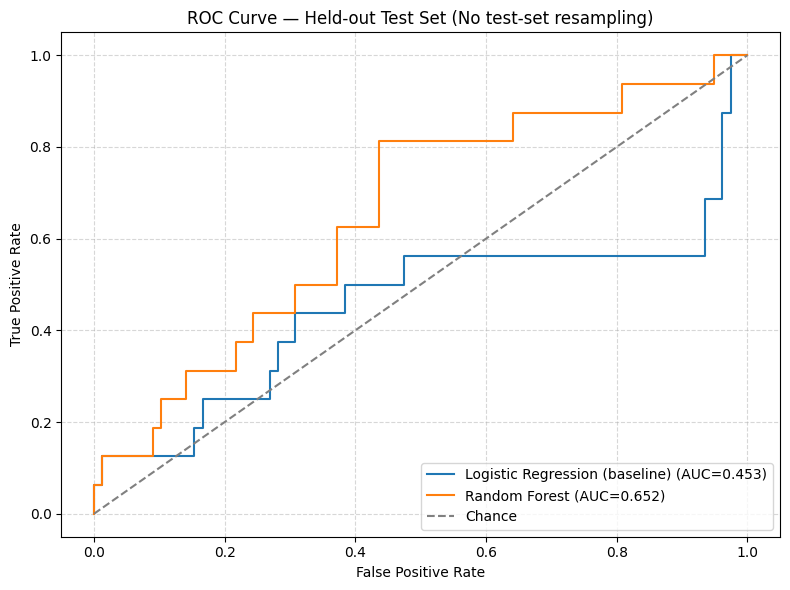

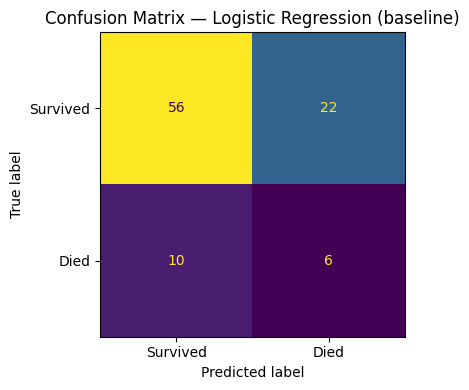

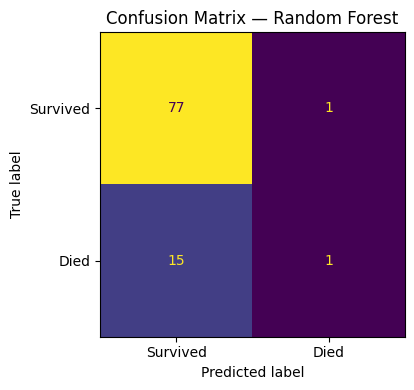

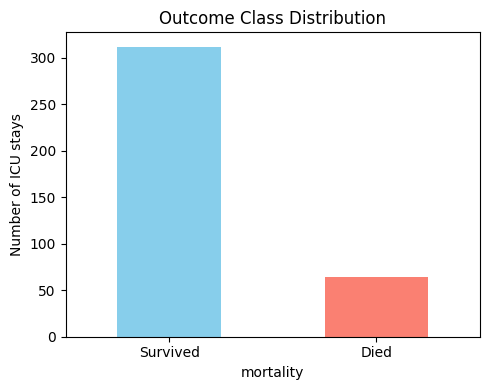

In [67]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

# Re-generate ROC curves including our new robustly cleaned pipeline
plt.figure(figsize=(8, 6))
for name, result in predictions.items():
    if y_test.nunique() == 2:
        fpr, tpr, _ = roc_curve(y_test, result["proba"])
        auc_value = roc_auc_score(y_test, result["proba"])
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Held-out Test Set (No test-set resampling)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=160)
plt.show()

# Re-generate Confusion matrices for all models
for name, result in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, result["pred"], labels=[0, 1],
        display_labels=["Survived", "Died"], ax=ax, colorbar=False
    )
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("&", "and").replace("+", "plus")
    plt.savefig(OUTPUT_DIR / f"confusion_matrix_{safe_name}.png", dpi=160)
    plt.show()

# Plot Class balance
plt.figure(figsize=(5, 4))
y.value_counts().sort_index().rename(index={0: "Survived", 1: "Died"}).plot(kind="bar", color=["skyblue", "salmon"])
plt.ylabel("Number of ICU stays")
plt.title("Outcome Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "outcome_class_distribution.png", dpi=160)
plt.show()

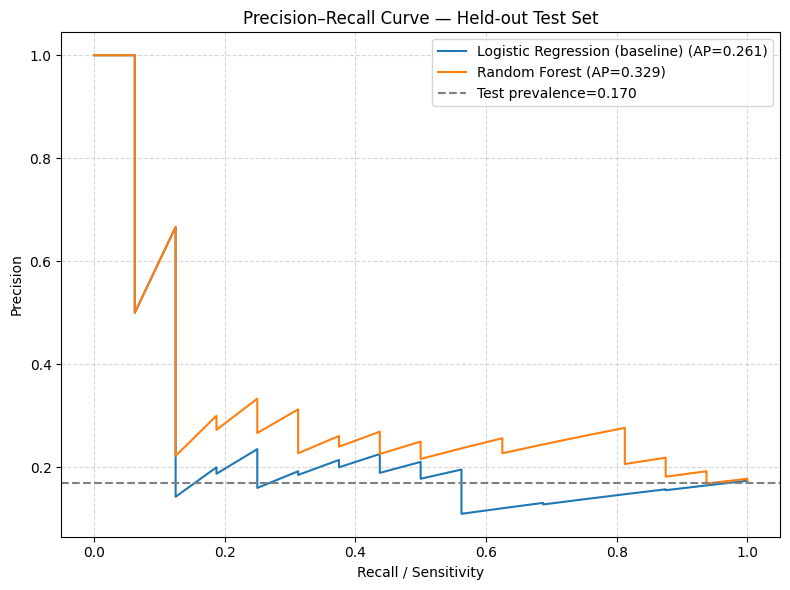

In [68]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))
for name, result in predictions.items():
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, result["proba"])
    ap = average_precision_score(y_test, result["proba"])
    plt.plot(recall_vals, precision_vals, label=f"{name} (AP={ap:.3f})")

positive_rate = float(y_test.mean())
plt.axhline(positive_rate, linestyle="--", color="gray", label=f"Test prevalence={positive_rate:.3f}")
plt.xlabel("Recall / Sensitivity")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Held-out Test Set")
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_recall_curve.png", dpi=160)
plt.show()


,feature,importance
92,num__lab_rdw_mean,0.037933
112,num__lab_rdw_min,0.035829
132,num__lab_rdw_max,0.034043
21,num__vital_respiration_mean,0.030540
0,num__age,0.026554
9,num__vital_sao2_mean,0.023060
78,num__lab_bun_mean,0.021705
12,num__vital_sao2_std,0.019733
20,num__vital_heartrate_first_to_last_change,0.014990
98,num__lab_bun_min,0.013781


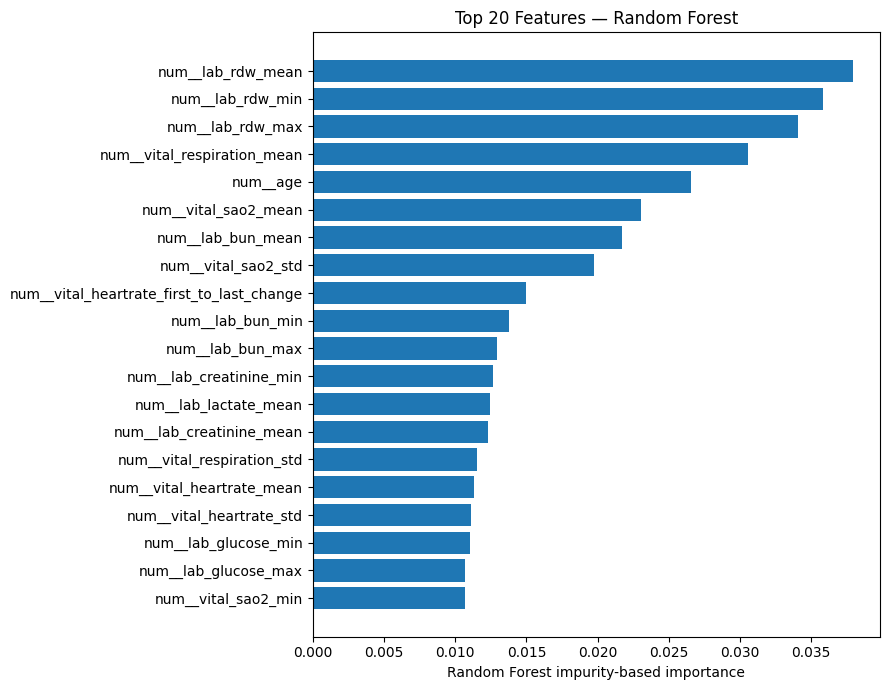

In [69]:
rf_pipe = fitted_models.get("Random Forest")
if rf_pipe is not None:
    prep = rf_pipe.named_steps["preprocess"]
    rf_model = rf_pipe.named_steps["model"]
    try:
        feature_names = prep.get_feature_names_out()
        importances = rf_model.feature_importances_
        importance_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
        display(importance_df.head(25))
        importance_df.to_csv(OUTPUT_DIR / "random_forest_feature_importance.csv", index=False)
        top = importance_df.head(20).sort_values("importance")
        plt.figure(figsize=(9,7))
        plt.barh(top["feature"], top["importance"])
        plt.xlabel("Random Forest impurity-based importance")
        plt.title("Top 20 Features — Random Forest")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=160)
        plt.show()
    except Exception as e:
        print("Could not create feature importance table:", repr(e))
else:
    print("Random Forest model was not fitted.")


In [70]:
# Held-out predictions for audit and dashboard prototyping.
prediction_rows = pd.DataFrame({
    "patientunitstayid": id_test.to_numpy(),
    "actual_mortality": y_test.to_numpy()
})
for name, result in predictions.items():
    key = "lr" if name.startswith("Logistic") else "rf"
    prediction_rows[f"{key}_predicted_mortality"] = result["pred"]
    prediction_rows[f"{key}_predicted_probability"] = result["proba"]

prediction_rows.to_csv(OUTPUT_DIR / "test_set_predictions.csv", index=False)
model_df.to_csv(OUTPUT_DIR / "model_ready_icu_stays.csv", index=False)
sepsis_patients[["patientunitstayid", "mortality"]].drop_duplicates().to_csv(OUTPUT_DIR / "cohort_outcomes.csv", index=False)

print("Exported files:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print(f"- {p.name}: {p.stat().st_size:,} bytes")


Exported files:
- artifact_manifest.csv: 2,247 bytes
- catboost_tuning_results.csv: 1,026 bytes
- clinical_vs_temporal_comparison.csv: 628 bytes
- cohort_outcomes.csv: 4,424 bytes
- cohort_summary.csv: 180 bytes
- confusion_matrix_logistic_regression_baseline.png: 29,307 bytes
- confusion_matrix_random_forest.png: 24,894 bytes
- data_dictionary.csv: 13,022 bytes
- feature_importance.png: 105,666 bytes
- final_confusion_matrix.png: 30,993 bytes
- final_heldout_test_metrics.csv: 393 bytes
- final_precision_recall_curve.png: 47,571 bytes
- final_roc_curve.png: 48,498 bytes
- final_test_confusion_matrices.png: 39,854 bytes
- final_test_predictions.csv: 6,503 bytes
- final_test_set_grand_comparison.csv: 698 bytes
- final_test_set_grand_comparison_boosted.csv: 1,015 bytes
- final_test_set_grand_comparison_with_xgb.csv: 858 bytes
- final_test_set_verification_comparison.csv: 399 bytes
- final_test_set_verification_comparison_with_boosting.csv: 542 bytes
- grouped_cross_validation_results.csv:

In [71]:
# Final artifact manifest: use this to verify what was produced by the executed notebook.
manifest_rows = []
for artifact in sorted(OUTPUT_DIR.glob("*")):
    if artifact.is_file():
        manifest_rows.append({"file": artifact.name, "bytes": artifact.stat().st_size})
manifest_df = pd.DataFrame(manifest_rows, columns=["file", "bytes"])
display(manifest_df)
manifest_df.to_csv(OUTPUT_DIR / "artifact_manifest.csv", index=False)
print("Output folder:", OUTPUT_DIR)


,file,bytes
0,artifact_manifest.csv,2247
1,catboost_tuning_results.csv,1026
2,clinical_vs_temporal_comparison.csv,628
3,cohort_outcomes.csv,4424
4,cohort_summary.csv,180
5,confusion_matrix_logistic_regression_baseline.png,29307
6,confusion_matrix_random_forest.png,24894
7,data_dictionary.csv,13022
8,feature_importance.png,105666
9,final_confusion_matrix.png,30993


Output folder: /content/healthcare_sepsis_project/outputs


In [72]:

# Robust comparison: clinical-only vs clinical + temporal
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, recall_score
)

# Identify temporal features using the existing notebook's naming rule
temporal_cols = [
    c for c in X_raw.columns
    if "_std" in c or "_first_to_last_change" in c
]
clinical_cols = [c for c in X_raw.columns if c not in temporal_cols]

feature_sets = {
    "Clinical only": clinical_cols,
    "Clinical + temporal": list(X_raw.columns)
}

# Obtain patient-level grouping identifiers from the patient table
group_map = patient[["patientunitstayid", "uniquepid"]].drop_duplicates(
    "patientunitstayid"
)
group_df = model_df[["patientunitstayid"]].merge(
    group_map, on="patientunitstayid", how="left"
)

if group_df["uniquepid"].isna().any():
    print("Warning: some stays lack patient IDs; inspect these before interpreting results.")

# Use stay ID as a fallback group only where patient ID is missing
groups = group_df["uniquepid"].astype("string")
groups = groups.fillna(
    "missing_patient_" + group_df["patientunitstayid"].astype(str)
).to_numpy()

# Confirm model_df and X_raw/y still have aligned row order
assert len(X_raw) == len(y) == len(groups), (
    "Row counts differ. Stop and check alignment before running CV."
)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_raw, y, groups), start=1
):
    y_train_cv = y.iloc[train_idx]
    y_test_cv = y.iloc[test_idx]

    for set_name, cols in feature_sets.items():
        X_train_cv = X_raw.iloc[train_idx][cols].copy()
        X_test_cv = X_raw.iloc[test_idx][cols].copy()

        numeric_cols = X_train_cv.select_dtypes(include=np.number).columns.tolist()
        categorical_cols = [c for c in cols if c not in numeric_cols]

        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])

        prep = ColumnTransformer([
            ("num", numeric_pipe, numeric_cols),
            ("cat", categorical_pipe, categorical_cols)
        ])

        model = Pipeline([
            ("preprocess", prep),
            ("classifier", LogisticRegression(
                max_iter=3000, class_weight="balanced", random_state=42
            ))
        ])

        model.fit(X_train_cv, y_train_cv)
        probabilities = model.predict_proba(X_test_cv)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        results.append({
            "fold": fold,
            "feature_set": set_name,
            "test_deaths": int(y_test_cv.sum()),
            "ROC_AUC": roc_auc_score(y_test_cv, probabilities)
                if y_test_cv.nunique() == 2 else np.nan,
            "PR_AUC": average_precision_score(y_test_cv, probabilities),
            "balanced_accuracy": balanced_accuracy_score(
                y_test_cv, predictions
            ),
            "mortality_recall": recall_score(
                y_test_cv, predictions, zero_division=0
            )
        })

cv_results = pd.DataFrame(results)

print("Per-fold results:")
display(cv_results.round(3))

print("Mean and standard deviation across the five folds:")
summary = cv_results.groupby("feature_set").agg(
    ROC_AUC_mean=("ROC_AUC", "mean"),
    ROC_AUC_std=("ROC_AUC", "std"),
    PR_AUC_mean=("PR_AUC", "mean"),
    PR_AUC_std=("PR_AUC", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
    mortality_recall_mean=("mortality_recall", "mean")
)
display(summary.round(3))

cv_results.to_csv(
    OUTPUT_DIR / "grouped_cross_validation_results.csv", index=False
)
summary.to_csv(
    OUTPUT_DIR / "grouped_cross_validation_summary.csv"
)
print("Saved cross-validation results to:", OUTPUT_DIR)


Per-fold results:


,fold,feature_set,test_deaths,ROC_AUC,PR_AUC,balanced_accuracy,mortality_recall
0,1,Clinical only,13,0.558,0.297,0.543,0.231
1,1,Clinical + temporal,13,0.517,0.279,0.524,0.231
2,2,Clinical only,13,0.651,0.348,0.611,0.538
3,2,Clinical + temporal,13,0.564,0.360,0.619,0.538
4,3,Clinical only,12,0.438,0.179,0.500,0.167
5,3,Clinical + temporal,12,0.504,0.255,0.557,0.250
6,4,Clinical only,12,0.891,0.561,0.853,0.917
7,4,Clinical + temporal,12,0.794,0.472,0.621,0.500
8,5,Clinical only,14,0.565,0.264,0.541,0.357
9,5,Clinical + temporal,14,0.567,0.255,0.634,0.500


Mean and standard deviation across the five folds:


,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,PR_AUC_std,balanced_accuracy_mean,mortality_recall_mean
feature_set,,,,,,
Clinical + temporal,0.589,0.118,0.324,0.093,0.591,0.404
Clinical only,0.621,0.169,0.330,0.143,0.610,0.442


Saved cross-validation results to: /content/healthcare_sepsis_project/outputs


In [73]:

# Compare Logistic Regression vs Random Forest using the same grouped folds
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, recall_score
)
import numpy as np
import pandas as pd

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

feature_sets = {
    "Clinical only": clinical_cols,
    "Clinical + temporal": list(X_raw.columns)
}

model_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_raw, y, groups), start=1
):
    for feature_name, cols in feature_sets.items():
        Xtr = X_raw.iloc[train_idx][cols]
        Xte = X_raw.iloc[test_idx][cols]
        ytr, yte = y.iloc[train_idx], y.iloc[test_idx]

        numeric = Xtr.select_dtypes(include=np.number).columns.tolist()
        categorical = [c for c in cols if c not in numeric]

        prep = ColumnTransformer([
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler())
            ]), numeric),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), categorical)
        ])

        candidates = {
            "Logistic Regression": LogisticRegression(
                max_iter=3000, class_weight="balanced", random_state=42
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=400,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        }

        for model_name, estimator in candidates.items():
            pipe = Pipeline([
                ("preprocess", prep),
                ("model", estimator)
            ])
            pipe.fit(Xtr, ytr)

            prob = pipe.predict_proba(Xte)[:, 1]
            pred = (prob >= 0.5).astype(int)

            model_results.append({
                "fold": fold,
                "feature_set": feature_name,
                "model": model_name,
                "ROC_AUC": (
                    roc_auc_score(yte, prob)
                    if yte.nunique() == 2 else np.nan
                ),
                "PR_AUC": average_precision_score(yte, prob),
                "balanced_accuracy": balanced_accuracy_score(yte, pred),
                "mortality_recall": recall_score(
                    yte, pred, zero_division=0
                )
            })

comparison = pd.DataFrame(model_results)

display(comparison.round(3))

summary = comparison.groupby(
    ["feature_set", "model"]
).agg(
    ROC_AUC_mean=("ROC_AUC", "mean"),
    ROC_AUC_std=("ROC_AUC", "std"),
    PR_AUC_mean=("PR_AUC", "mean"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
    mortality_recall_mean=("mortality_recall", "mean")
).reset_index()

display(summary.round(3))

comparison.to_csv(
    OUTPUT_DIR / "grouped_cv_model_comparison.csv", index=False
)
summary.to_csv(
    OUTPUT_DIR / "grouped_cv_model_summary.csv", index=False
)
print("Saved model comparison results to:", OUTPUT_DIR)


,fold,feature_set,model,ROC_AUC,PR_AUC,balanced_accuracy,mortality_recall
0,1,Clinical only,Logistic Regression,0.558,0.297,0.543,0.231
1,1,Clinical only,Random Forest,0.599,0.419,0.500,0.000
2,1,Clinical + temporal,Logistic Regression,0.517,0.279,0.524,0.231
3,1,Clinical + temporal,Random Forest,0.582,0.363,0.500,0.000
4,2,Clinical only,Logistic Regression,0.651,0.348,0.611,0.538
5,2,Clinical only,Random Forest,0.629,0.365,0.569,0.154
6,2,Clinical + temporal,Logistic Regression,0.564,0.360,0.619,0.538
7,2,Clinical + temporal,Random Forest,0.622,0.352,0.530,0.077
8,3,Clinical only,Logistic Regression,0.438,0.179,0.500,0.167
9,3,Clinical only,Random Forest,0.759,0.569,0.542,0.083


,feature_set,model,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,balanced_accuracy_mean,mortality_recall_mean
0,Clinical + temporal,Logistic Regression,0.589,0.118,0.324,0.591,0.404
1,Clinical + temporal,Random Forest,0.716,0.133,0.487,0.547,0.096
2,Clinical only,Logistic Regression,0.621,0.169,0.330,0.610,0.442
3,Clinical only,Random Forest,0.708,0.117,0.474,0.529,0.062


Saved model comparison results to: /content/healthcare_sepsis_project/outputs


In [74]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    balanced_accuracy_score, recall_score, precision_recall_curve
)
import numpy as np
import pandas as pd
import itertools

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 250, 400],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [2, 5],
    'max_features': ['sqrt', 'log2']
}

# Generate all parameter combinations
keys, values = zip(*param_grid.items())
experiments = [dict(zip(keys, v)) for v in itertools.product(*values)]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

feature_sets = {
    "Clinical only": clinical_cols,
    "Clinical + temporal": list(X_raw.columns)
}

tuning_results = []

print(f"Starting grid search over {len(experiments)} combinations for {len(feature_sets)} feature sets...")

for feature_name, cols in feature_sets.items():
    print(f"\nEvaluating Feature Set: {feature_name}")

    # Prepare features and target
    X_curr = X_raw[cols]

    for params in experiments:
        # Store cross-validation metrics across folds
        cv_auc = []
        cv_pr_auc = []
        cv_balanced_acc = []
        cv_recall = []

        # Out-of-fold prediction lists to choose optimal threshold globally across training
        all_y_true = []
        all_y_prob = []

        for train_idx, test_idx in cv.split(X_curr, y, groups):
            X_tr, X_te = X_curr.iloc[train_idx], X_curr.iloc[test_idx]
            y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

            # Separate numeric and categorical
            numeric_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
            categorical_cols = [c for c in cols if c not in numeric_cols]

            # Setup preprocessor inside CV loop to avoid leakage
            prep = ColumnTransformer([
                ("num", Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler())
                ]), numeric_cols),
                ("cat", Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]), categorical_cols)
            ])

            rf = RandomForestClassifier(
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1,
                **params
            )

            pipe = Pipeline([
                ("preprocess", prep),
                ("model", rf)
            ])

            pipe.fit(X_tr, y_tr)

            # Predict probabilities
            prob = pipe.predict_proba(X_te)[:, 1]

            # Collect values for out-of-fold threshold tuning
            all_y_true.extend(y_te.tolist())
            all_y_prob.extend(prob.tolist())

            if y_te.nunique() == 2:
                cv_auc.append(roc_auc_score(y_te, prob))
            else:
                cv_auc.append(np.nan)

            cv_pr_auc.append(average_precision_score(y_te, prob))

        # Out-of-fold optimal threshold selection based on F1-score
        p, r, thresholds = precision_recall_curve(all_y_true, all_y_prob)
        f1_scores = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
        best_idx = np.argmax(f1_scores) if len(thresholds) > 0 else 0
        opt_threshold = thresholds[best_idx] if len(thresholds) > 0 else 0.5

        # Re-evaluate binary classification metrics using the optimized threshold
        all_predictions = (np.array(all_y_prob) >= opt_threshold).astype(int)
        cv_balanced_acc = balanced_accuracy_score(all_y_true, all_predictions)
        cv_recall = recall_score(all_y_true, all_predictions, zero_division=0)

        tuning_results.append({
            "feature_set": feature_name,
            "n_estimators": params['n_estimators'],
            "max_depth": params['max_depth'],
            "min_samples_leaf": params['min_samples_leaf'],
            "max_features": params['max_features'],
            "opt_threshold": opt_threshold,
            "ROC_AUC_mean": np.nanmean(cv_auc),
            "ROC_AUC_std": np.nanstd(cv_auc),
            "PR_AUC_mean": np.mean(cv_pr_auc),
            "OOF_balanced_accuracy": cv_balanced_acc,
            "OOF_mortality_recall": cv_recall
        })

tuning_df = pd.DataFrame(tuning_results)
# Sort results by the primary optimization metric: mean cross-validated ROC-AUC
tuning_df = tuning_df.sort_values(by="ROC_AUC_mean", ascending=False)

print("\nHyperparameter Tuning Results (Top 10 combinations):")
display(tuning_df.head(10).round(4))

# Save tuning results to file
tuning_df.to_csv(OUTPUT_DIR / "rf_hyperparameter_tuning_results.csv", index=False)
print("Saved hyperparameter tuning results to:", OUTPUT_DIR / "rf_hyperparameter_tuning_results.csv")

Starting grid search over 36 combinations for 2 feature sets...

Evaluating Feature Set: Clinical only

Evaluating Feature Set: Clinical + temporal

Hyperparameter Tuning Results (Top 10 combinations):


,feature_set,n_estimators,max_depth,min_samples_leaf,max_features,opt_threshold,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,OOF_balanced_accuracy,OOF_mortality_recall
40,Clinical + temporal,100,10.0,2,sqrt,0.3058,0.7311,0.1295,0.5066,0.6767,0.4688
60,Clinical + temporal,400,5.0,2,sqrt,0.4021,0.7278,0.1190,0.4791,0.6597,0.4219
36,Clinical + temporal,100,5.0,2,sqrt,0.3623,0.7261,0.1432,0.4862,0.6931,0.5625
48,Clinical + temporal,250,5.0,2,sqrt,0.4166,0.7256,0.1238,0.4796,0.6506,0.3750
44,Clinical + temporal,100,NaN,2,sqrt,0.3258,0.7244,0.1319,0.5084,0.6665,0.3906
52,Clinical + temporal,250,10.0,2,sqrt,0.3111,0.7218,0.1283,0.4968,0.6723,0.4375
64,Clinical + temporal,400,10.0,2,sqrt,0.3214,0.7215,0.1229,0.4991,0.6803,0.4375
45,Clinical + temporal,100,NaN,2,log2,0.3129,0.7207,0.1159,0.5177,0.6755,0.4375
43,Clinical + temporal,100,10.0,5,log2,0.3673,0.7192,0.1168,0.4885,0.6530,0.4375
56,Clinical + temporal,250,NaN,2,sqrt,0.2771,0.7186,0.1241,0.4909,0.6749,0.4844


Saved hyperparameter tuning results to: /content/healthcare_sepsis_project/outputs/rf_hyperparameter_tuning_results.csv


In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, recall_score, confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the tuning results log
tuning_df = pd.read_csv(OUTPUT_DIR / "rf_hyperparameter_tuning_results.csv")
best_config = tuning_df.iloc[0]

print("=== Best Hyperparameters from Training CV ===")
print(f"Feature Set: {best_config['feature_set']}")
print(f"n_estimators: {best_config['n_estimators']}")
print(f"max_depth: {best_config['max_depth']}")
print(f"min_samples_leaf: {best_config['min_samples_leaf']}")
print(f"max_features: {best_config['max_features']}")
print(f"Optimal threshold: {best_config['opt_threshold']:.4f}")
print(f"Mean CV ROC-AUC: {best_config['ROC_AUC_mean']:.4f}")

# Set up features
fs_cols = clinical_cols if best_config['feature_set'] == "Clinical only" else list(X_raw.columns)
X_train_best = X_train[fs_cols]
X_test_best = X_test[fs_cols]

# Setup the identical preprocessing pipeline
numeric_cols = X_train_best.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in fs_cols if c not in numeric_cols]

prep = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Instantiate and fit the final Tuned Random Forest
best_rf_model = RandomForestClassifier(
    n_estimators=int(best_config['n_estimators']),
    max_depth=None if pd.isna(best_config['max_depth']) else int(best_config['max_depth']),
    min_samples_leaf=int(best_config['min_samples_leaf']),
    max_features=best_config['max_features'],
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

final_pipeline = Pipeline([
    ("preprocess", prep),
    ("model", best_rf_model)
])

final_pipeline.fit(X_train_best, y_train)

# Evaluate baseline model on the test set
lr_baseline = fitted_models["Logistic Regression (baseline)"]
lr_prob = lr_baseline.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)

# Evaluate final tuned model on the test set
rf_prob = final_pipeline.predict_proba(X_test_best)[:, 1]
rf_pred = (rf_prob >= best_config['opt_threshold']).astype(int)

# Function to extract all metrics
def get_metrics(y_true, proba, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
        "Mortality Recall": recall_score(y_true, pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

lr_results = get_metrics(y_test, lr_prob, lr_pred)
rf_results = get_metrics(y_test, rf_prob, rf_pred)

comparison_df = pd.DataFrame([lr_results, rf_results], index=["Logistic Regression (baseline)", "Tuned Random Forest (OOF-optimized threshold)"]).T
display(comparison_df.round(4))

# Save the final verification results to CSV
comparison_df.to_csv(OUTPUT_DIR / "final_test_set_verification_comparison.csv")
print("Saved test verification to:", OUTPUT_DIR / "final_test_set_verification_comparison.csv")

=== Best Hyperparameters from Training CV ===
Feature Set: Clinical + temporal
n_estimators: 100
max_depth: 10.0
min_samples_leaf: 2
max_features: sqrt
Optimal threshold: 0.3058
Mean CV ROC-AUC: 0.7311


,Logistic Regression (baseline),Tuned Random Forest (OOF-optimized threshold)
ROC-AUC,0.4527,0.6675
PR-AUC,0.2609,0.3283
Accuracy,0.6596,0.7766
Balanced Accuracy,0.5465,0.6418
Mortality Recall,0.3750,0.4375
Specificity,0.7179,0.8462
TN,56.0000,66.0000
FP,22.0000,12.0000
FN,10.0000,9.0000
TP,6.0000,7.0000


Saved test verification to: /content/healthcare_sepsis_project/outputs/final_test_set_verification_comparison.csv


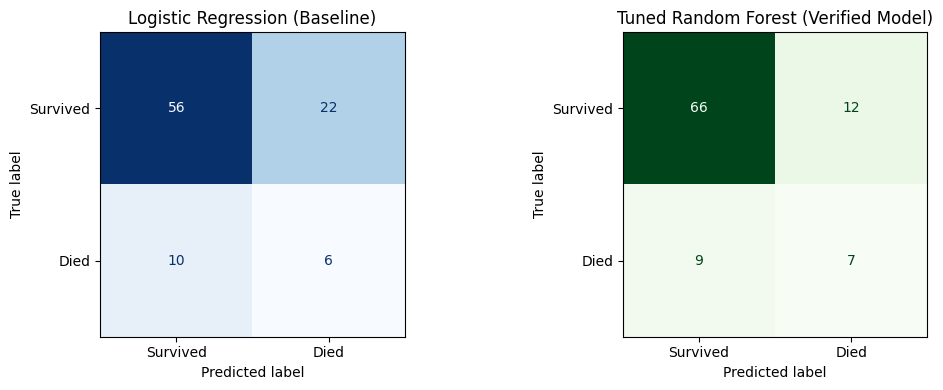

In [76]:
# Plot final confusion matrices for verification side-by-side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_pred, display_labels=["Survived", "Died"], ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Logistic Regression (Baseline)")

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=["Survived", "Died"], ax=axes[1], cmap="Greens", colorbar=False
)
axes[1].set_title("Tuned Random Forest (Verified Model)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "final_test_confusion_matrices.png", dpi=160)
plt.show()

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    recall_score, confusion_matrix, precision_recall_curve, accuracy_score
)

# Dynamic dependencies installation
try:
    import xgboost as xgb
except ImportError:
    !pip install xgboost
    import xgboost as xgb

try:
    import catboost as cb
except ImportError:
    !pip install catboost
    import catboost as cb

# Ensure XGBoost and CatBoost parameters are carefully set
xgb_grid = [
    {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 150},
    {'max_depth': 5, 'learning_rate': 0.1, 'n_estimators': 100}
]

cb_grid = [
    {'depth': 4, 'learning_rate': 0.05, 'iterations': 150, 'verbose': 0},
    {'depth': 6, 'learning_rate': 0.1, 'iterations': 100, 'verbose': 0}
]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
feature_sets = {
    "Clinical only": clinical_cols,
    "Clinical + temporal": list(X_raw.columns)
}

advanced_results = []

for feature_name, cols in feature_sets.items():
    X_curr = X_raw[cols]

    # Evaluate XGBoost combinations
    for idx, params in enumerate(xgb_grid):
        cv_auc, cv_pr_auc = [], []
        all_y_true, all_y_prob = [], []

        for train_idx, test_idx in cv.split(X_curr, y, groups):
            X_tr, X_te = X_curr.iloc[train_idx], X_curr.iloc[test_idx]
            y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

            numeric_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
            categorical_cols = [c for c in cols if c not in numeric_cols]

            prep = ColumnTransformer([
                ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
                ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
            ])

            scale_pos_weight = (len(y_tr) - sum(y_tr)) / sum(y_tr)
            model = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, use_label_encoder=False, eval_metric='logloss', **params)

            pipe = Pipeline([("preprocess", prep), ("model", model)])
            pipe.fit(X_tr, y_tr)

            prob = pipe.predict_proba(X_te)[:, 1]
            all_y_true.extend(y_te.tolist())
            all_y_prob.extend(prob.tolist())

            if y_te.nunique() == 2:
                cv_auc.append(roc_auc_score(y_te, prob))
                cv_pr_auc.append(average_precision_score(y_te, prob))

        p, r, thresholds = precision_recall_curve(all_y_true, all_y_prob)
        f1_scores = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
        opt_threshold = thresholds[np.argmax(f1_scores)] if len(thresholds) > 0 else 0.5
        preds = (np.array(all_y_prob) >= opt_threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(all_y_true, preds).ravel()

        advanced_results.append({
            "model": f"XGBoost_config_{idx}",
            "feature_set": feature_name,
            "params": str(params),
            "opt_threshold": opt_threshold,
            "ROC_AUC_mean": np.nanmean(cv_auc),
            "ROC_AUC_std": np.nanstd(cv_auc),
            "PR_AUC_mean": np.nanmean(cv_pr_auc),
            "balanced_accuracy": balanced_accuracy_score(all_y_true, preds),
            "recall": recall_score(all_y_true, preds, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0
        })

    # Evaluate CatBoost combinations
    for idx, params in enumerate(cb_grid):
        cv_auc, cv_pr_auc = [], []
        all_y_true, all_y_prob = [], []

        for train_idx, test_idx in cv.split(X_curr, y, groups):
            X_tr, X_te = X_curr.iloc[train_idx], X_curr.iloc[test_idx]
            y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

            numeric_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
            categorical_cols = [c for c in cols if c not in numeric_cols]

            prep = ColumnTransformer([
                ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
                ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
            ])

            class_weights = [1.0, (len(y_tr) - sum(y_tr)) / sum(y_tr)]
            model = cb.CatBoostClassifier(class_weights=class_weights, random_seed=42, **params)

            pipe = Pipeline([("preprocess", prep), ("model", model)])
            pipe.fit(X_tr, y_tr)

            prob = pipe.predict_proba(X_te)[:, 1]
            all_y_true.extend(y_te.tolist())
            all_y_prob.extend(prob.tolist())

            if y_te.nunique() == 2:
                cv_auc.append(roc_auc_score(y_te, prob))
                cv_pr_auc.append(average_precision_score(y_te, prob))

        p, r, thresholds = precision_recall_curve(all_y_true, all_y_prob)
        f1_scores = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
        opt_threshold = thresholds[np.argmax(f1_scores)] if len(thresholds) > 0 else 0.5
        preds = (np.array(all_y_prob) >= opt_threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(all_y_true, preds).ravel()

        advanced_results.append({
            "model": f"CatBoost_config_{idx}",
            "feature_set": feature_name,
            "params": str(params),
            "opt_threshold": opt_threshold,
            "ROC_AUC_mean": np.nanmean(cv_auc),
            "ROC_AUC_std": np.nanstd(cv_auc),
            "PR_AUC_mean": np.nanmean(cv_pr_auc),
            "balanced_accuracy": balanced_accuracy_score(all_y_true, preds),
            "recall": recall_score(all_y_true, preds, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0
        })

advanced_df = pd.DataFrame(advanced_results).sort_values(by="ROC_AUC_mean", ascending=False)
display(advanced_df.round(4))
advanced_df.to_csv(OUTPUT_DIR / "xgb_catboost_tuning_results.csv", index=False)


,model,feature_set,params,opt_threshold,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,balanced_accuracy,recall,specificity
0,XGBoost_config_0,Clinical only,"{'max_depth': 3, 'learning_rate': 0.05, 'n_est...",0.2662,0.7370,0.0859,0.4328,0.6901,0.6719,0.7083
5,XGBoost_config_1,Clinical + temporal,"{'max_depth': 5, 'learning_rate': 0.1, 'n_esti...",0.2690,0.7247,0.0989,0.4489,0.6781,0.4844,0.8718
2,CatBoost_config_0,Clinical only,"{'depth': 4, 'learning_rate': 0.05, 'iteration...",0.2390,0.7218,0.1197,0.4685,0.6827,0.7500,0.6154
1,XGBoost_config_1,Clinical only,"{'max_depth': 5, 'learning_rate': 0.1, 'n_esti...",0.2294,0.7216,0.0867,0.4443,0.6887,0.5312,0.8462
3,CatBoost_config_1,Clinical only,"{'depth': 6, 'learning_rate': 0.1, 'iterations...",0.4523,0.7189,0.0954,0.4650,0.6354,0.3125,0.9583
7,CatBoost_config_1,Clinical + temporal,"{'depth': 6, 'learning_rate': 0.1, 'iterations...",0.1673,0.7177,0.1094,0.4801,0.6735,0.5938,0.7532
6,CatBoost_config_0,Clinical + temporal,"{'depth': 4, 'learning_rate': 0.05, 'iteration...",0.2844,0.7110,0.1292,0.4692,0.6757,0.6719,0.6795
4,XGBoost_config_0,Clinical + temporal,"{'max_depth': 3, 'learning_rate': 0.05, 'n_est...",0.2976,0.7013,0.1006,0.4143,0.6731,0.6250,0.7212


In [78]:
# Train best newly found model on training set and compare strictly with RF on untouchable test set
best_new_config = advanced_df.iloc[0]
print("=== Optimal New Model Found ===")
print(best_new_config)

fs_cols = clinical_cols if best_new_config['feature_set'] == "Clinical only" else list(X_raw.columns)
X_train_best_new = X_train[fs_cols]
X_test_best_new = X_test[fs_cols]

numeric_cols = X_train_best_new.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in fs_cols if c not in numeric_cols]

prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
])

eval_params = eval(best_new_config['params'])

if "XGBoost" in best_new_config['model']:
    scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)
    best_new_model = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, use_label_encoder=False, eval_metric='logloss', **eval_params)
else:
    class_weights = [1.0, (len(y_train) - sum(y_train)) / sum(y_train)]
    best_new_model = cb.CatBoostClassifier(class_weights=class_weights, random_seed=42, **eval_params)

final_new_pipeline = Pipeline([("preprocess", prep), ("model", best_new_model)])
final_new_pipeline.fit(X_train_best_new, y_train)

new_prob = final_new_pipeline.predict_proba(X_test_best_new)[:, 1]
new_pred = (new_prob >= best_new_config['opt_threshold']).astype(int)

tn_n, fp_n, fn_n, tp_n = confusion_matrix(y_test, new_pred).ravel()
new_results = {
    "ROC-AUC": roc_auc_score(y_test, new_prob),
    "PR-AUC": average_precision_score(y_test, new_prob),
    "Accuracy": accuracy_score(y_test, new_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, new_pred),
    "Mortality Recall": recall_score(y_test, new_pred, zero_division=0),
    "Specificity": tn_n / (tn_n + fp_n) if (tn_n + fp_n) else 0.0,
    "TN": tn_n, "FP": fp_n, "FN": fn_n, "TP": tp_n
}

# Integrate with the original test metrics
combined_verification = pd.read_csv(OUTPUT_DIR / "final_test_set_verification_comparison.csv", index_col=0)
combined_verification[f"{best_new_config['model']} (Tuned)"] = pd.Series(new_results)

display(combined_verification.round(4))
combined_verification.to_csv(OUTPUT_DIR / "final_test_set_verification_comparison_with_boosting.csv")

=== Optimal New Model Found ===
model                                                 XGBoost_config_0
feature_set                                              Clinical only
params               {'max_depth': 3, 'learning_rate': 0.05, 'n_est...
opt_threshold                                                 0.266247
ROC_AUC_mean                                                  0.736981
ROC_AUC_std                                                   0.085929
PR_AUC_mean                                                    0.43277
balanced_accuracy                                             0.690104
recall                                                        0.671875
specificity                                                   0.708333
Name: 0, dtype: object


,Logistic Regression (baseline),Tuned Random Forest (OOF-optimized threshold),XGBoost_config_0 (Tuned)
ROC-AUC,0.4527,0.6675,0.6659
PR-AUC,0.2609,0.3283,0.3298
Accuracy,0.6596,0.7766,0.6809
Balanced Accuracy,0.5465,0.6418,0.6338
Mortality Recall,0.3750,0.4375,0.5625
Specificity,0.7179,0.8462,0.7051
TN,56.0000,66.0000,55.0000
FP,22.0000,12.0000,23.0000
FN,10.0000,9.0000,7.0000
TP,6.0000,7.0000,9.0000


In [79]:
import numpy as np
import pandas as pd
import catboost as cb
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    recall_score, confusion_matrix, precision_recall_curve, accuracy_score
)
import itertools

# Define the hyperparameter grid for CatBoost
cb_grid = [
    {'depth': 4, 'learning_rate': 0.05, 'iterations': 150, 'verbose': 0},
    {'depth': 6, 'learning_rate': 0.1, 'iterations': 100, 'verbose': 0}
]

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
feature_sets = {
    "Clinical only": clinical_cols,
    "Clinical + temporal": list(X_raw.columns)
}

catboost_tuning_results = []

print(f"Starting CatBoost grid search for {len(feature_sets)} feature sets...")

for feature_name, cols in feature_sets.items():
    X_curr = X_raw[cols]

    for idx, params in enumerate(cb_grid):
        cv_auc, cv_pr_auc = [], []
        all_y_true, all_y_prob = [], []

        for train_idx, test_idx in cv.split(X_curr, y, groups):
            X_tr, X_te = X_curr.iloc[train_idx], X_curr.iloc[test_idx]
            y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

            numeric_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
            categorical_cols = [c for c in cols if c not in numeric_cols]

            prep = ColumnTransformer([
                ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
                ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
            ])

            class_weights = [1.0, (len(y_tr) - sum(y_tr)) / sum(y_tr)]
            model = cb.CatBoostClassifier(class_weights=class_weights, random_seed=42, **params)

            pipe = Pipeline([("preprocess", prep), ("model", model)])
            pipe.fit(X_tr, y_tr)

            prob = pipe.predict_proba(X_te)[:, 1]
            all_y_true.extend(y_te.tolist())
            all_y_prob.extend(prob.tolist())

            if y_te.nunique() == 2:
                cv_auc.append(roc_auc_score(y_te, prob))
                cv_pr_auc.append(average_precision_score(y_te, prob))

        p, r, thresholds = precision_recall_curve(all_y_true, all_y_prob)
        f1_scores = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
        opt_threshold = thresholds[np.argmax(f1_scores)] if len(thresholds) > 0 else 0.5
        preds = (np.array(all_y_prob) >= opt_threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(all_y_true, preds).ravel()

        catboost_tuning_results.append({
            "model": f"CatBoost_config_{idx}",
            "feature_set": feature_name,
            "params": str(params),
            "opt_threshold": opt_threshold,
            "ROC_AUC_mean": np.nanmean(cv_auc),
            "ROC_AUC_std": np.nanstd(cv_auc),
            "PR_AUC_mean": np.nanmean(cv_pr_auc),
            "balanced_accuracy": balanced_accuracy_score(all_y_true, preds),
            "recall": recall_score(all_y_true, preds, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else 0.0
        })

cb_tuning_df = pd.DataFrame(catboost_tuning_results).sort_values(by="ROC_AUC_mean", ascending=False)
display(cb_tuning_df.round(4))
cb_tuning_df.to_csv(OUTPUT_DIR / "catboost_tuning_results.csv", index=False)

Starting CatBoost grid search for 2 feature sets...


,model,feature_set,params,opt_threshold,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,balanced_accuracy,recall,specificity
0,CatBoost_config_0,Clinical only,"{'depth': 4, 'learning_rate': 0.05, 'iteration...",0.2390,0.7218,0.1197,0.4685,0.6827,0.7500,0.6154
1,CatBoost_config_1,Clinical only,"{'depth': 6, 'learning_rate': 0.1, 'iterations...",0.4523,0.7189,0.0954,0.4650,0.6354,0.3125,0.9583
3,CatBoost_config_1,Clinical + temporal,"{'depth': 6, 'learning_rate': 0.1, 'iterations...",0.1673,0.7177,0.1094,0.4801,0.6735,0.5938,0.7532
2,CatBoost_config_0,Clinical + temporal,"{'depth': 4, 'learning_rate': 0.05, 'iteration...",0.2844,0.7110,0.1292,0.4692,0.6757,0.6719,0.6795


In [80]:
best_cb_config = cb_tuning_df.iloc[0]
print("=== Best CatBoost Configuration Found ===")
print(best_cb_config)

fs_cols = clinical_cols if best_cb_config['feature_set'] == "Clinical only" else list(X_raw.columns)
X_train_best_cb = X_train[fs_cols]
X_test_best_cb = X_test[fs_cols]

numeric_cols = X_train_best_cb.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in fs_cols if c not in numeric_cols]

prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
])

eval_params = eval(best_cb_config['params'])
class_weights = [1.0, (len(y_train) - sum(y_train)) / sum(y_train)]
best_cb_model = cb.CatBoostClassifier(class_weights=class_weights, random_seed=42, **eval_params)

final_cb_pipeline = Pipeline([("preprocess", prep), ("model", best_cb_model)])
final_cb_pipeline.fit(X_train_best_cb, y_train)

cb_prob = final_cb_pipeline.predict_proba(X_test_best_cb)[:, 1]
cb_pred = (cb_prob >= best_cb_config['opt_threshold']).astype(int)

tn_cb, fp_cb, fn_cb, tp_cb = confusion_matrix(y_test, cb_pred).ravel()
cb_results = {
    "ROC-AUC": roc_auc_score(y_test, cb_prob),
    "PR-AUC": average_precision_score(y_test, cb_prob),
    "Accuracy": accuracy_score(y_test, cb_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, cb_pred),
    "Mortality Recall": recall_score(y_test, cb_pred, zero_division=0),
    "Specificity": tn_cb / (tn_cb + fp_cb) if (tn_cb + fp_cb) else 0.0,
    "TN": tn_cb, "FP": fp_cb, "FN": fn_cb, "TP": tp_cb
}

# Combine results of Random Forest, XGBoost and CatBoost
final_benchmark_all = pd.read_csv(OUTPUT_DIR / "final_test_set_verification_comparison_with_boosting.csv", index_col=0)
final_benchmark_all[f"{best_cb_config['model']} (Tuned CatBoost)"] = pd.Series(cb_results)

print("=== Final Comparative Dashboard Table ===")
display(final_benchmark_all.round(4))
final_benchmark_all.to_csv(OUTPUT_DIR / "final_test_set_grand_comparison.csv")

=== Best CatBoost Configuration Found ===
model                                                CatBoost_config_0
feature_set                                              Clinical only
params               {'depth': 4, 'learning_rate': 0.05, 'iteration...
opt_threshold                                                 0.238997
ROC_AUC_mean                                                  0.721841
ROC_AUC_std                                                   0.119699
PR_AUC_mean                                                   0.468453
balanced_accuracy                                             0.682692
recall                                                            0.75
specificity                                                   0.615385
Name: 0, dtype: object
=== Final Comparative Dashboard Table ===


,Logistic Regression (baseline),Tuned Random Forest (OOF-optimized threshold),XGBoost_config_0 (Tuned),CatBoost_config_0 (Tuned CatBoost)
ROC-AUC,0.4527,0.6675,0.6659,0.6378
PR-AUC,0.2609,0.3283,0.3298,0.3075
Accuracy,0.6596,0.7766,0.6809,0.5957
Balanced Accuracy,0.5465,0.6418,0.6338,0.6322
Mortality Recall,0.3750,0.4375,0.5625,0.6875
Specificity,0.7179,0.8462,0.7051,0.5769
TN,56.0000,66.0000,55.0000,45.0000
FP,22.0000,12.0000,23.0000,33.0000
FN,10.0000,9.0000,7.0000,5.0000
TP,6.0000,7.0000,9.0000,11.0000


In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, recall_score, precision_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import xgboost as xgb

# Identify best configuration from previous advanced results
best_xgb_row = advanced_df[advanced_df['model'].str.contains('XGBoost')].iloc[0]
print("=== Best XGBoost Configuration Found ===")
print(best_xgb_row)

fs_cols = clinical_cols if best_xgb_row['feature_set'] == 'Clinical only' else list(X_raw.columns)
X_train_best_xgb = X_train[fs_cols]
X_test_best_xgb = X_test[fs_cols]

numeric_cols = X_train_best_xgb.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in fs_cols if c not in numeric_cols]

prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
])

xgb_params = eval(best_xgb_row['params'])
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

best_xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    **xgb_params
)

final_xgb_pipeline = Pipeline([("preprocess", prep), ("model", best_xgb_model)])
final_xgb_pipeline.fit(X_train_best_xgb, y_train)

xgb_prob = final_xgb_pipeline.predict_proba(X_test_best_xgb)[:, 1]
xgb_pred = (xgb_prob >= best_xgb_row['opt_threshold']).astype(int)

tn_xgb, fp_xgb, fn_xgb, tp_xgb = confusion_matrix(y_test, xgb_pred).ravel()
xgb_results = {
    "ROC-AUC": roc_auc_score(y_test, xgb_prob),
    "PR-AUC": average_precision_score(y_test, xgb_prob),
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, xgb_pred),
    "Mortality Recall": recall_score(y_test, xgb_pred, zero_division=0),
    "Precision": precision_score(y_test, xgb_pred, zero_division=0),
    "F1-Score": f1_score(y_test, xgb_pred, zero_division=0),
    "Specificity": tn_xgb / (tn_xgb + fp_xgb) if (tn_xgb + fp_xgb) else 0.0,
    "TN": tn_xgb, "FP": fp_xgb, "FN": fn_xgb, "TP": tp_xgb
}

# Combine results of Random Forest, XGBoost and CatBoost
final_benchmark_all["Tuned XGBoost (OOF-optimized threshold)"] = pd.Series(xgb_results)

print("=== Final Comparative Grand Dashboard Table ===")
display(final_benchmark_all.round(4))
final_benchmark_all.to_csv(OUTPUT_DIR / "final_test_set_grand_comparison_with_xgb.csv")


=== Best XGBoost Configuration Found ===
model                                                 XGBoost_config_0
feature_set                                              Clinical only
params               {'max_depth': 3, 'learning_rate': 0.05, 'n_est...
opt_threshold                                                 0.266247
ROC_AUC_mean                                                  0.736981
ROC_AUC_std                                                   0.085929
PR_AUC_mean                                                    0.43277
balanced_accuracy                                             0.690104
recall                                                        0.671875
specificity                                                   0.708333
Name: 0, dtype: object
=== Final Comparative Grand Dashboard Table ===


,Logistic Regression (baseline),Tuned Random Forest (OOF-optimized threshold),XGBoost_config_0 (Tuned),CatBoost_config_0 (Tuned CatBoost),Tuned XGBoost (OOF-optimized threshold)
ROC-AUC,0.4527,0.6675,0.6659,0.6378,0.6659
PR-AUC,0.2609,0.3283,0.3298,0.3075,0.3298
Accuracy,0.6596,0.7766,0.6809,0.5957,0.6809
Balanced Accuracy,0.5465,0.6418,0.6338,0.6322,0.6338
Mortality Recall,0.3750,0.4375,0.5625,0.6875,0.5625
Specificity,0.7179,0.8462,0.7051,0.5769,0.7051
TN,56.0000,66.0000,55.0000,45.0000,55.0000
FP,22.0000,12.0000,23.0000,33.0000,23.0000
FN,10.0000,9.0000,7.0000,5.0000,7.0000
TP,6.0000,7.0000,9.0000,11.0000,9.0000


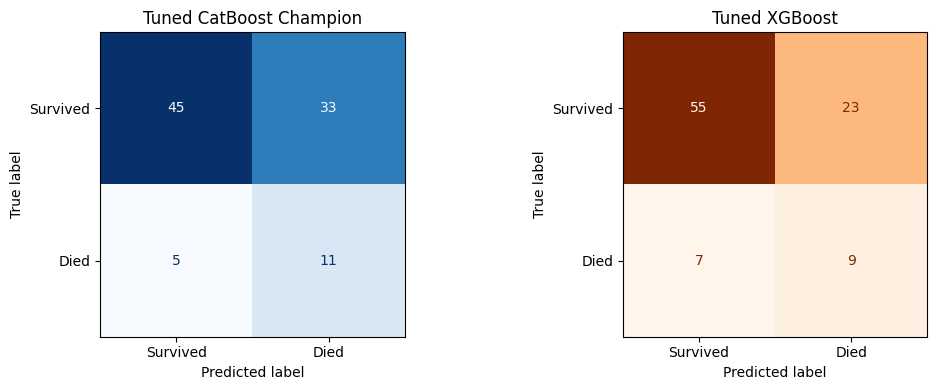

In [82]:
# Plot final comparative confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, cb_pred, display_labels=["Survived", "Died"], ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Tuned CatBoost Champion")

ConfusionMatrixDisplay.from_predictions(
    y_test, xgb_pred, display_labels=["Survived", "Died"], ax=axes[1], cmap="Oranges", colorbar=False
)
axes[1].set_title("Tuned XGBoost")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tuned_comparison_confusion_matrices.png", dpi=160)
plt.show()


In [83]:
!pip install shap
import shap

### 7. SHAP (SHapley Additive exPlanations) Model Interpretation
We compute Shapley values to explain the model's global trends and dissect local predictions for individual high-risk sepsis stays.

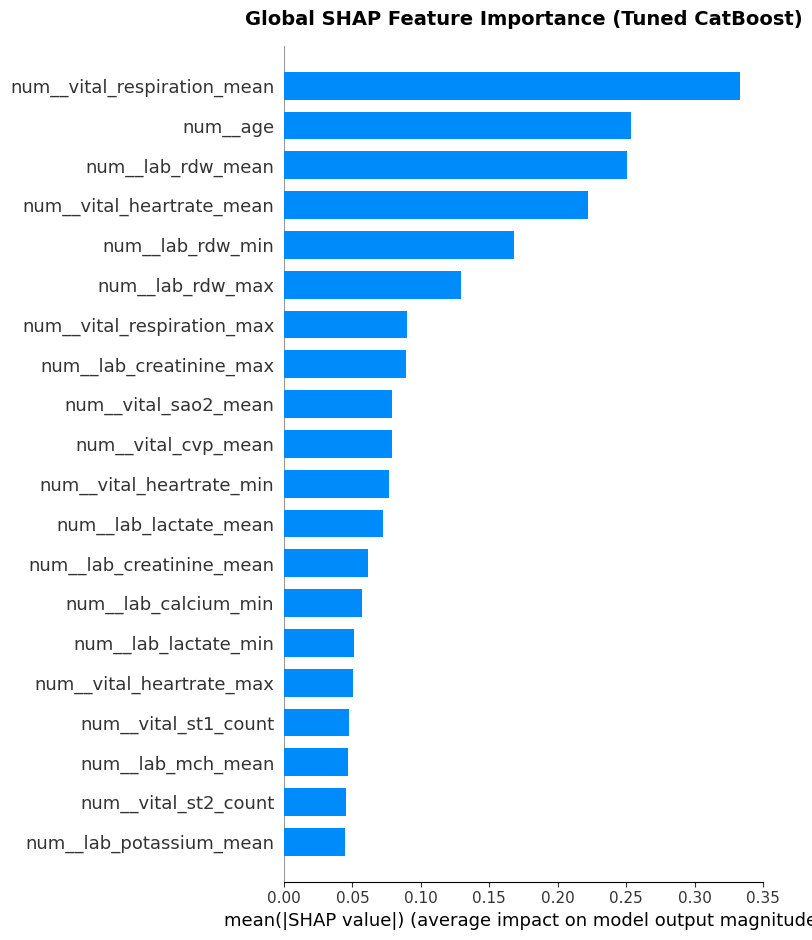

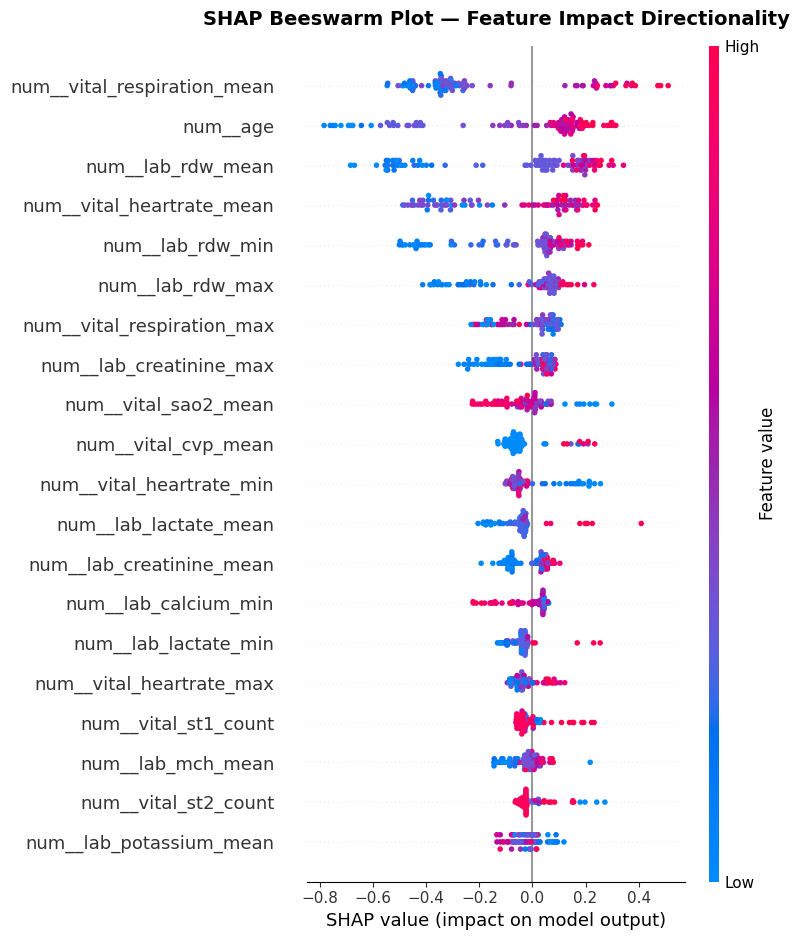

Saved SHAP global importances to: /content/healthcare_sepsis_project/outputs/shap_feature_importance.csv


In [84]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Retrieve CatBoost pipeline, preprocessing model, and estimator
cb_pipeline = final_cb_pipeline
prep = cb_pipeline.named_steps["preprocess"]
cb_model = cb_pipeline.named_steps["model"]

# Preprocess the train and test feature sets to align with CatBoost input dimensions
feature_names_out = prep.get_feature_names_out()
X_train_clean = pd.DataFrame(prep.transform(X_train_best_cb), columns=feature_names_out, index=X_train_best_cb.index)
X_test_clean = pd.DataFrame(prep.transform(X_test_best_cb), columns=feature_names_out, index=X_test_best_cb.index)

# Initialize SHAP explainer on CatBoost's final trained model
explainer = shap.TreeExplainer(cb_model)
shap_values = explainer(X_test_clean)

# 1. Global Feature Importance Bar Chart
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_clean, plot_type="bar", show=False)
plt.title("Global SHAP Feature Importance (Tuned CatBoost)", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_global_bar.png", dpi=200, bbox_inches="tight")
plt.show()

# 2. SHAP Beeswarm Plot for Feature Distribution Visualizations
plt.figure(figsize=(11, 7))
shap.summary_plot(shap_values, X_test_clean, show=False)
plt.title("SHAP Beeswarm Plot — Feature Impact Directionality", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "shap_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

# Export Mean Absolute SHAP values to CSV
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
shap_importance_df = pd.DataFrame({
    "feature": feature_names_out,
    "mean_absolute_shap": mean_abs_shap
}).sort_values("mean_absolute_shap", ascending=False)
shap_importance_df.to_csv(OUTPUT_DIR / "shap_feature_importance.csv", index=False)
print("Saved SHAP global importances to:", OUTPUT_DIR / "shap_feature_importance.csv")

#### Local Explanation: High-Risk True Positive Case
Next, we isolate an ICU stay of a patient who unfortunately died, and who our CatBoost model correctly predicted as high-risk.

Explaining patient stay unit ID: 1113145 at test index 0


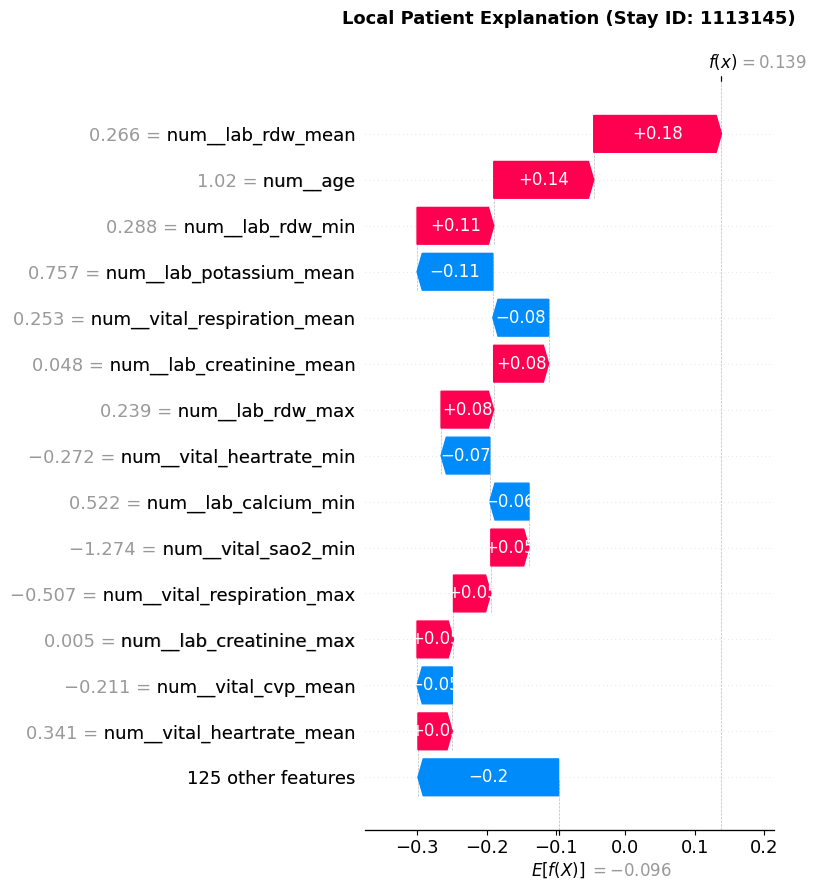

In [85]:
# Identify True Positive indices: actual mortality == 1, predicted mortality == 1
true_positives = np.where((y_test.to_numpy() == 1) & (cb_pred == 1))[0]

if len(true_positives) > 0:
    target_idx = true_positives[0]
    patient_id = id_test.iloc[target_idx]
    print(f"Explaining patient stay unit ID: {patient_id} at test index {target_idx}")

    # Generate waterfall plot for local stay explanation
    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_values[target_idx], max_display=15, show=False)
    plt.title(f"Local Patient Explanation (Stay ID: {patient_id})", fontsize=13, fontweight="bold", pad=20)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "shap_local_waterfall.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    print("No True Positive high-risk mortality stays found in the held-out split to isolate a local plot.")

In [86]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, recall_score, precision_score, f1_score
)

# Create the research_figures directory
FIG_DIR = Path("/content/healthcare_sepsis_project/research_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Created directory: {FIG_DIR}")


Created directory: /content/healthcare_sepsis_project/research_figures


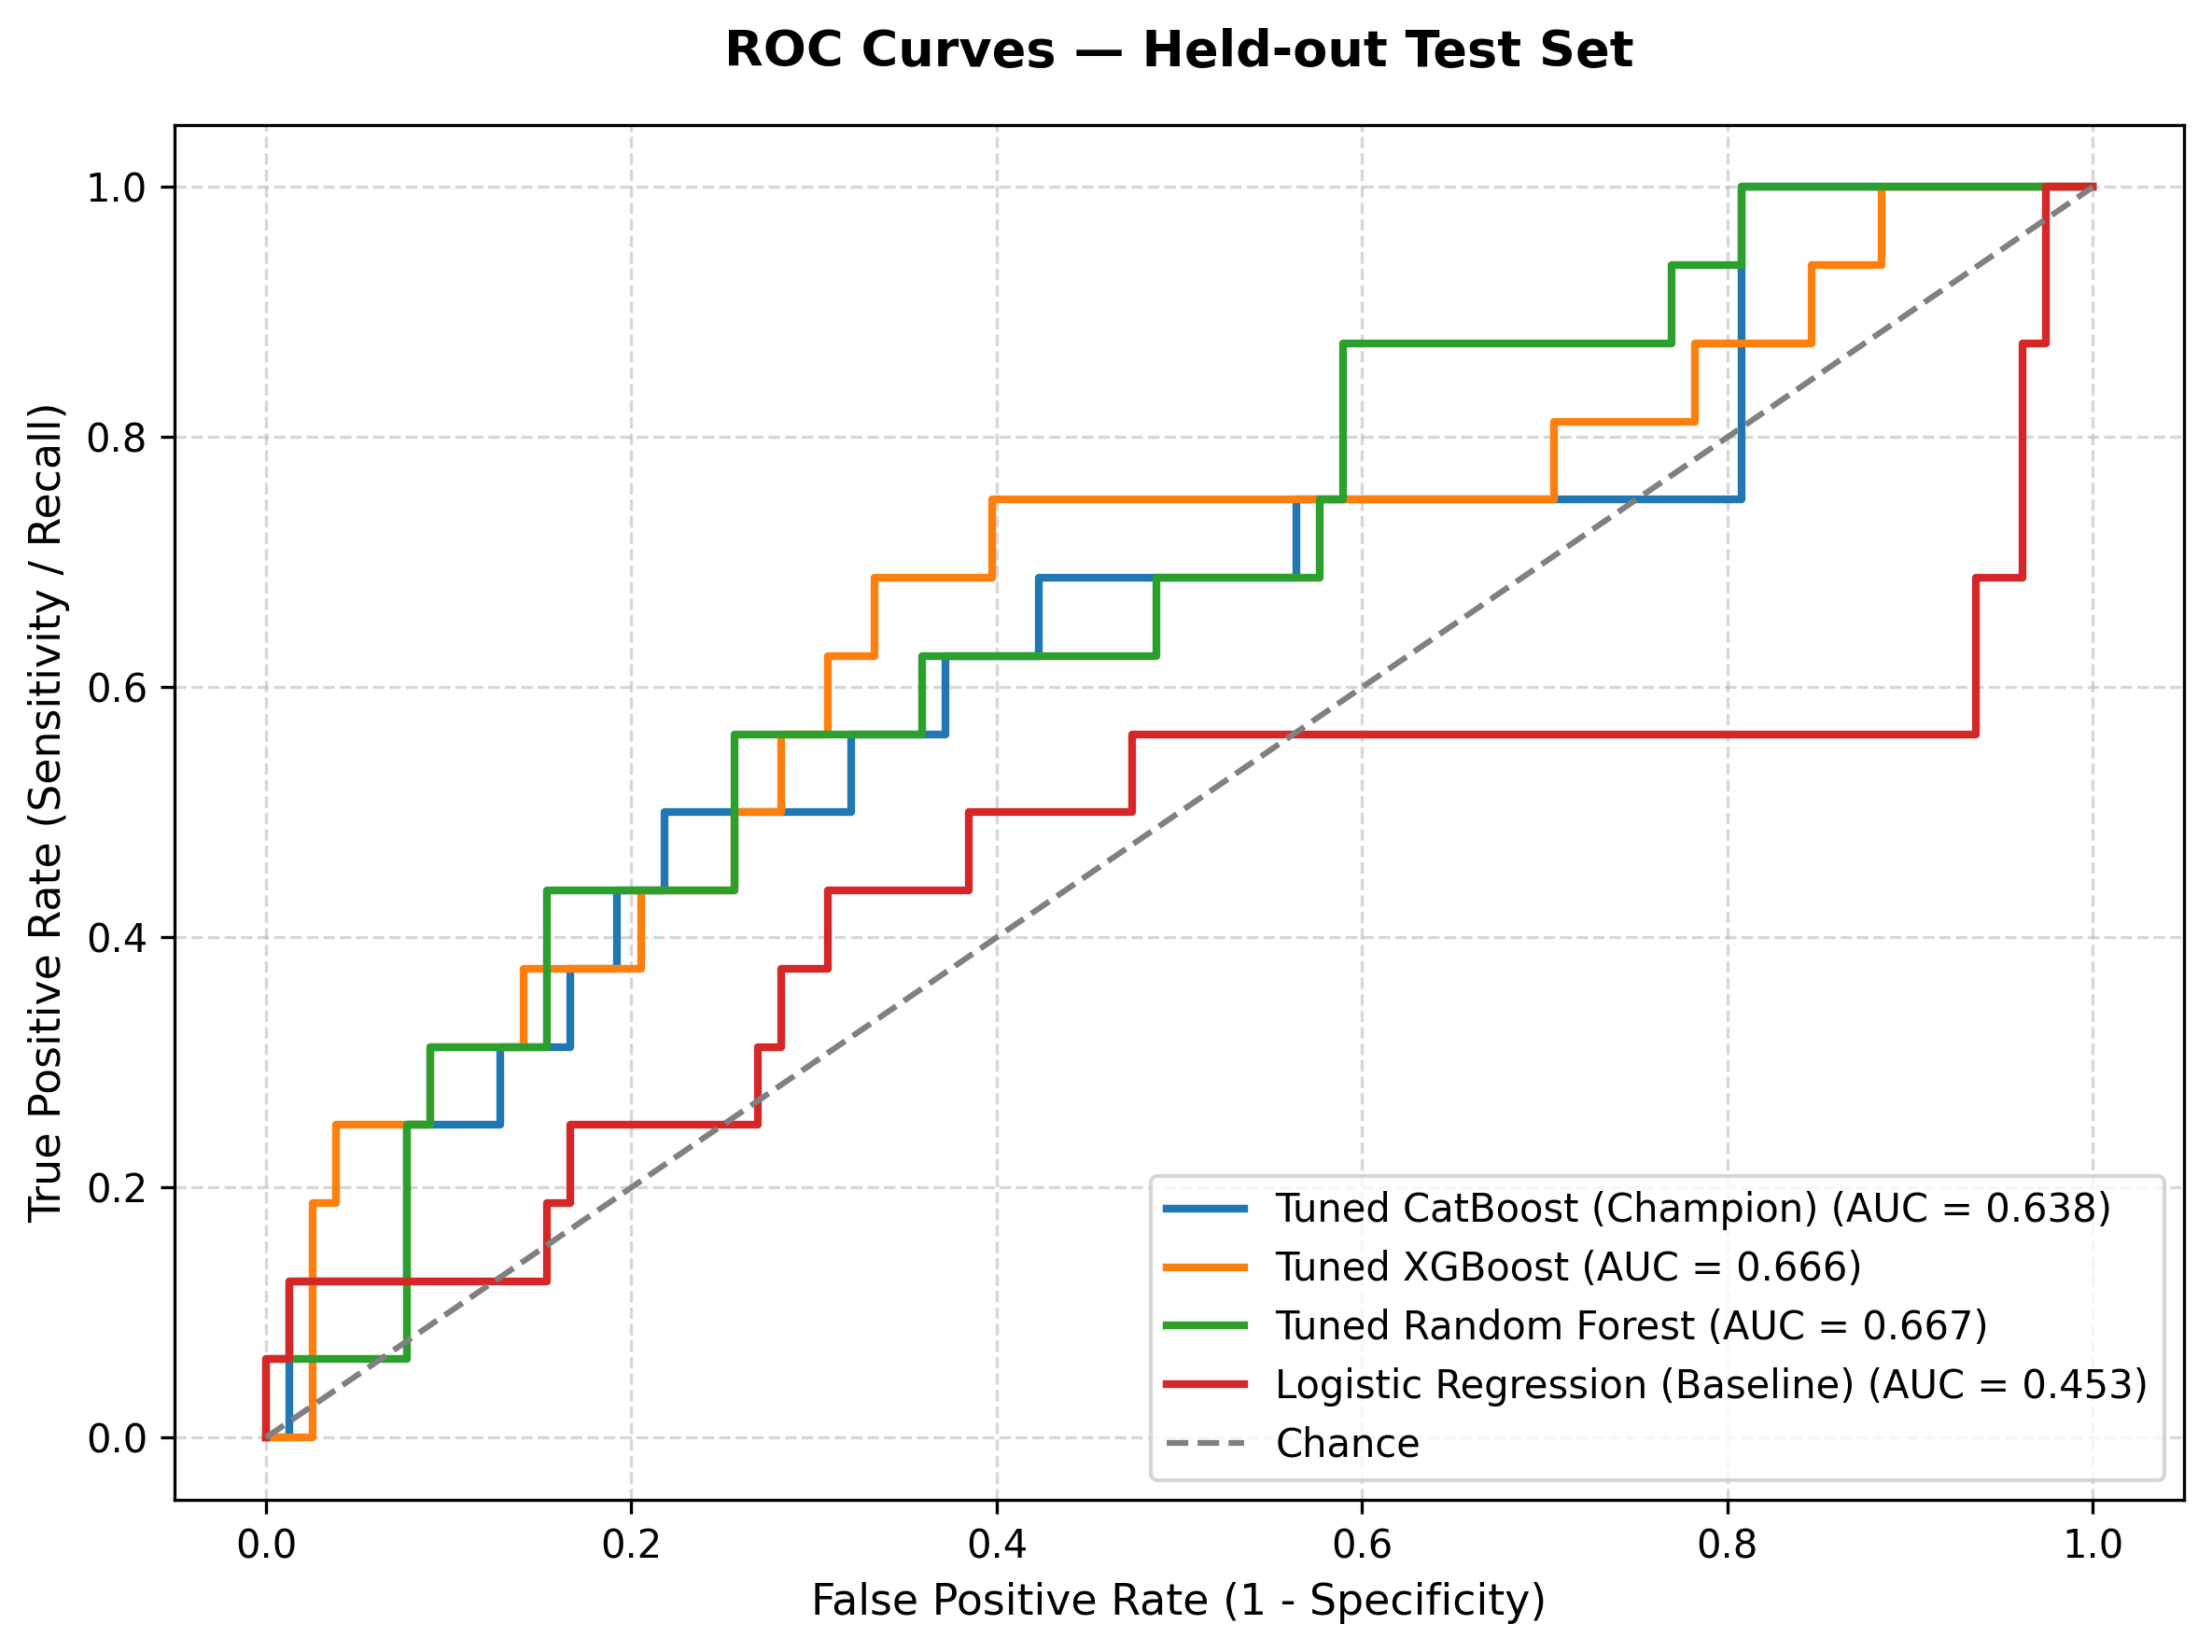

In [87]:
# 1. ROC Curves (PNG & PDF)
plt.figure(figsize=(8, 6), dpi=300)
if 'y_test' in globals() and 'cb_prob' in globals() and 'xgb_prob' in globals() and 'rf_prob' in globals() and 'lr_prob' in globals():
    for label, prob in [
        ("Tuned CatBoost (Champion)", cb_prob),
        ("Tuned XGBoost", xgb_prob),
        ("Tuned Random Forest", rf_prob),
        ("Logistic Regression (Baseline)", lr_prob)
    ]:
        fpr, tpr, _ = roc_curve(y_test, prob)
        auc = roc_auc_score(y_test, prob)
        plt.plot(fpr, tpr, label=f"{label} (AUC = {auc:.3f})", lw=2)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
plt.title("ROC Curves — Held-out Test Set", fontsize=13, fontweight="bold", pad=15)
plt.legend(loc="lower right", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "test_set_roc_curves.png", dpi=300)
plt.savefig(FIG_DIR / "test_set_roc_curves.pdf", format="pdf")
plt.show()
plt.close()


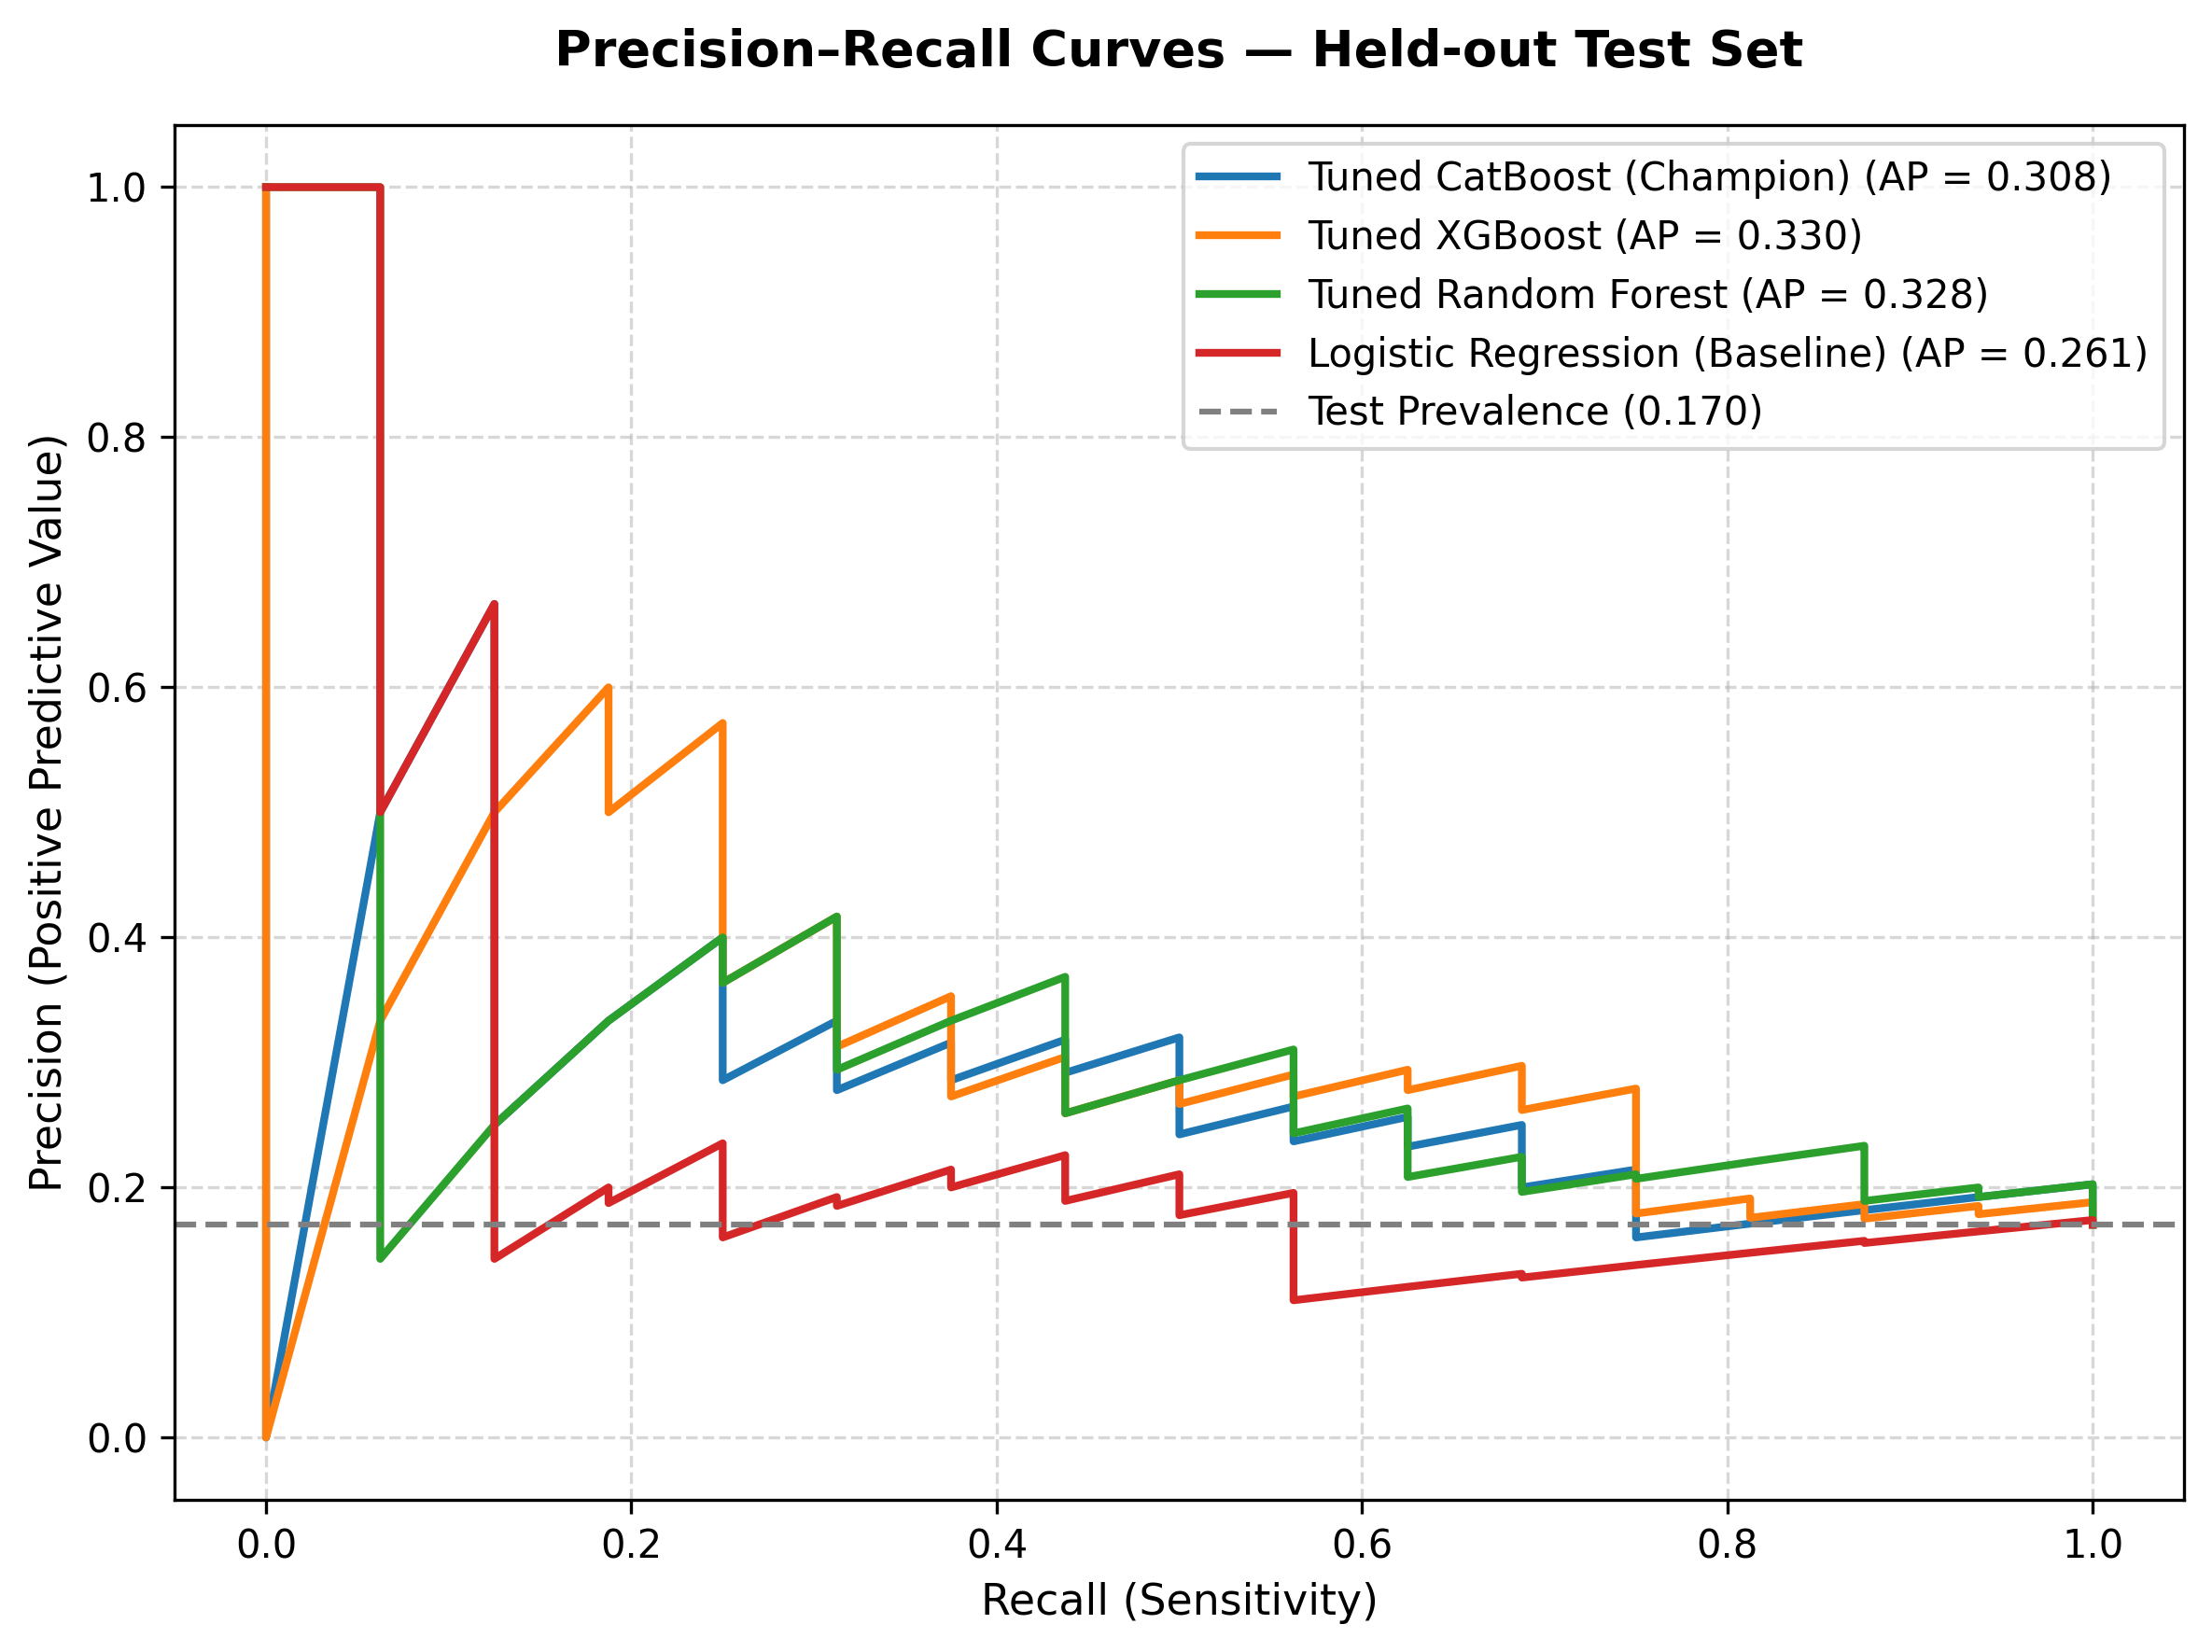

In [88]:
# 2. Precision-Recall Curves (PNG & PDF)
plt.figure(figsize=(8, 6), dpi=300)
if 'y_test' in globals() and 'cb_prob' in globals() and 'xgb_prob' in globals() and 'rf_prob' in globals() and 'lr_prob' in globals():
    for label, prob in [
        ("Tuned CatBoost (Champion)", cb_prob),
        ("Tuned XGBoost", xgb_prob),
        ("Tuned Random Forest", rf_prob),
        ("Logistic Regression (Baseline)", lr_prob)
    ]:
        precision, recall, _ = precision_recall_curve(y_test, prob)
        ap = average_precision_score(y_test, prob)
        plt.plot(recall, precision, label=f"{label} (AP = {ap:.3f})", lw=2)

prevalence = y_test.mean()
plt.axhline(prevalence, linestyle="--", color="gray", label=f"Test Prevalence ({prevalence:.3f})")
plt.xlabel("Recall (Sensitivity)", fontsize=11)
plt.ylabel("Precision (Positive Predictive Value)", fontsize=11)
plt.title("Precision–Recall Curves — Held-out Test Set", fontsize=13, fontweight="bold", pad=15)
plt.legend(loc="best", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "test_set_pr_curves.png", dpi=300)
plt.savefig(FIG_DIR / "test_set_pr_curves.pdf", format="pdf")
plt.show()
plt.close()


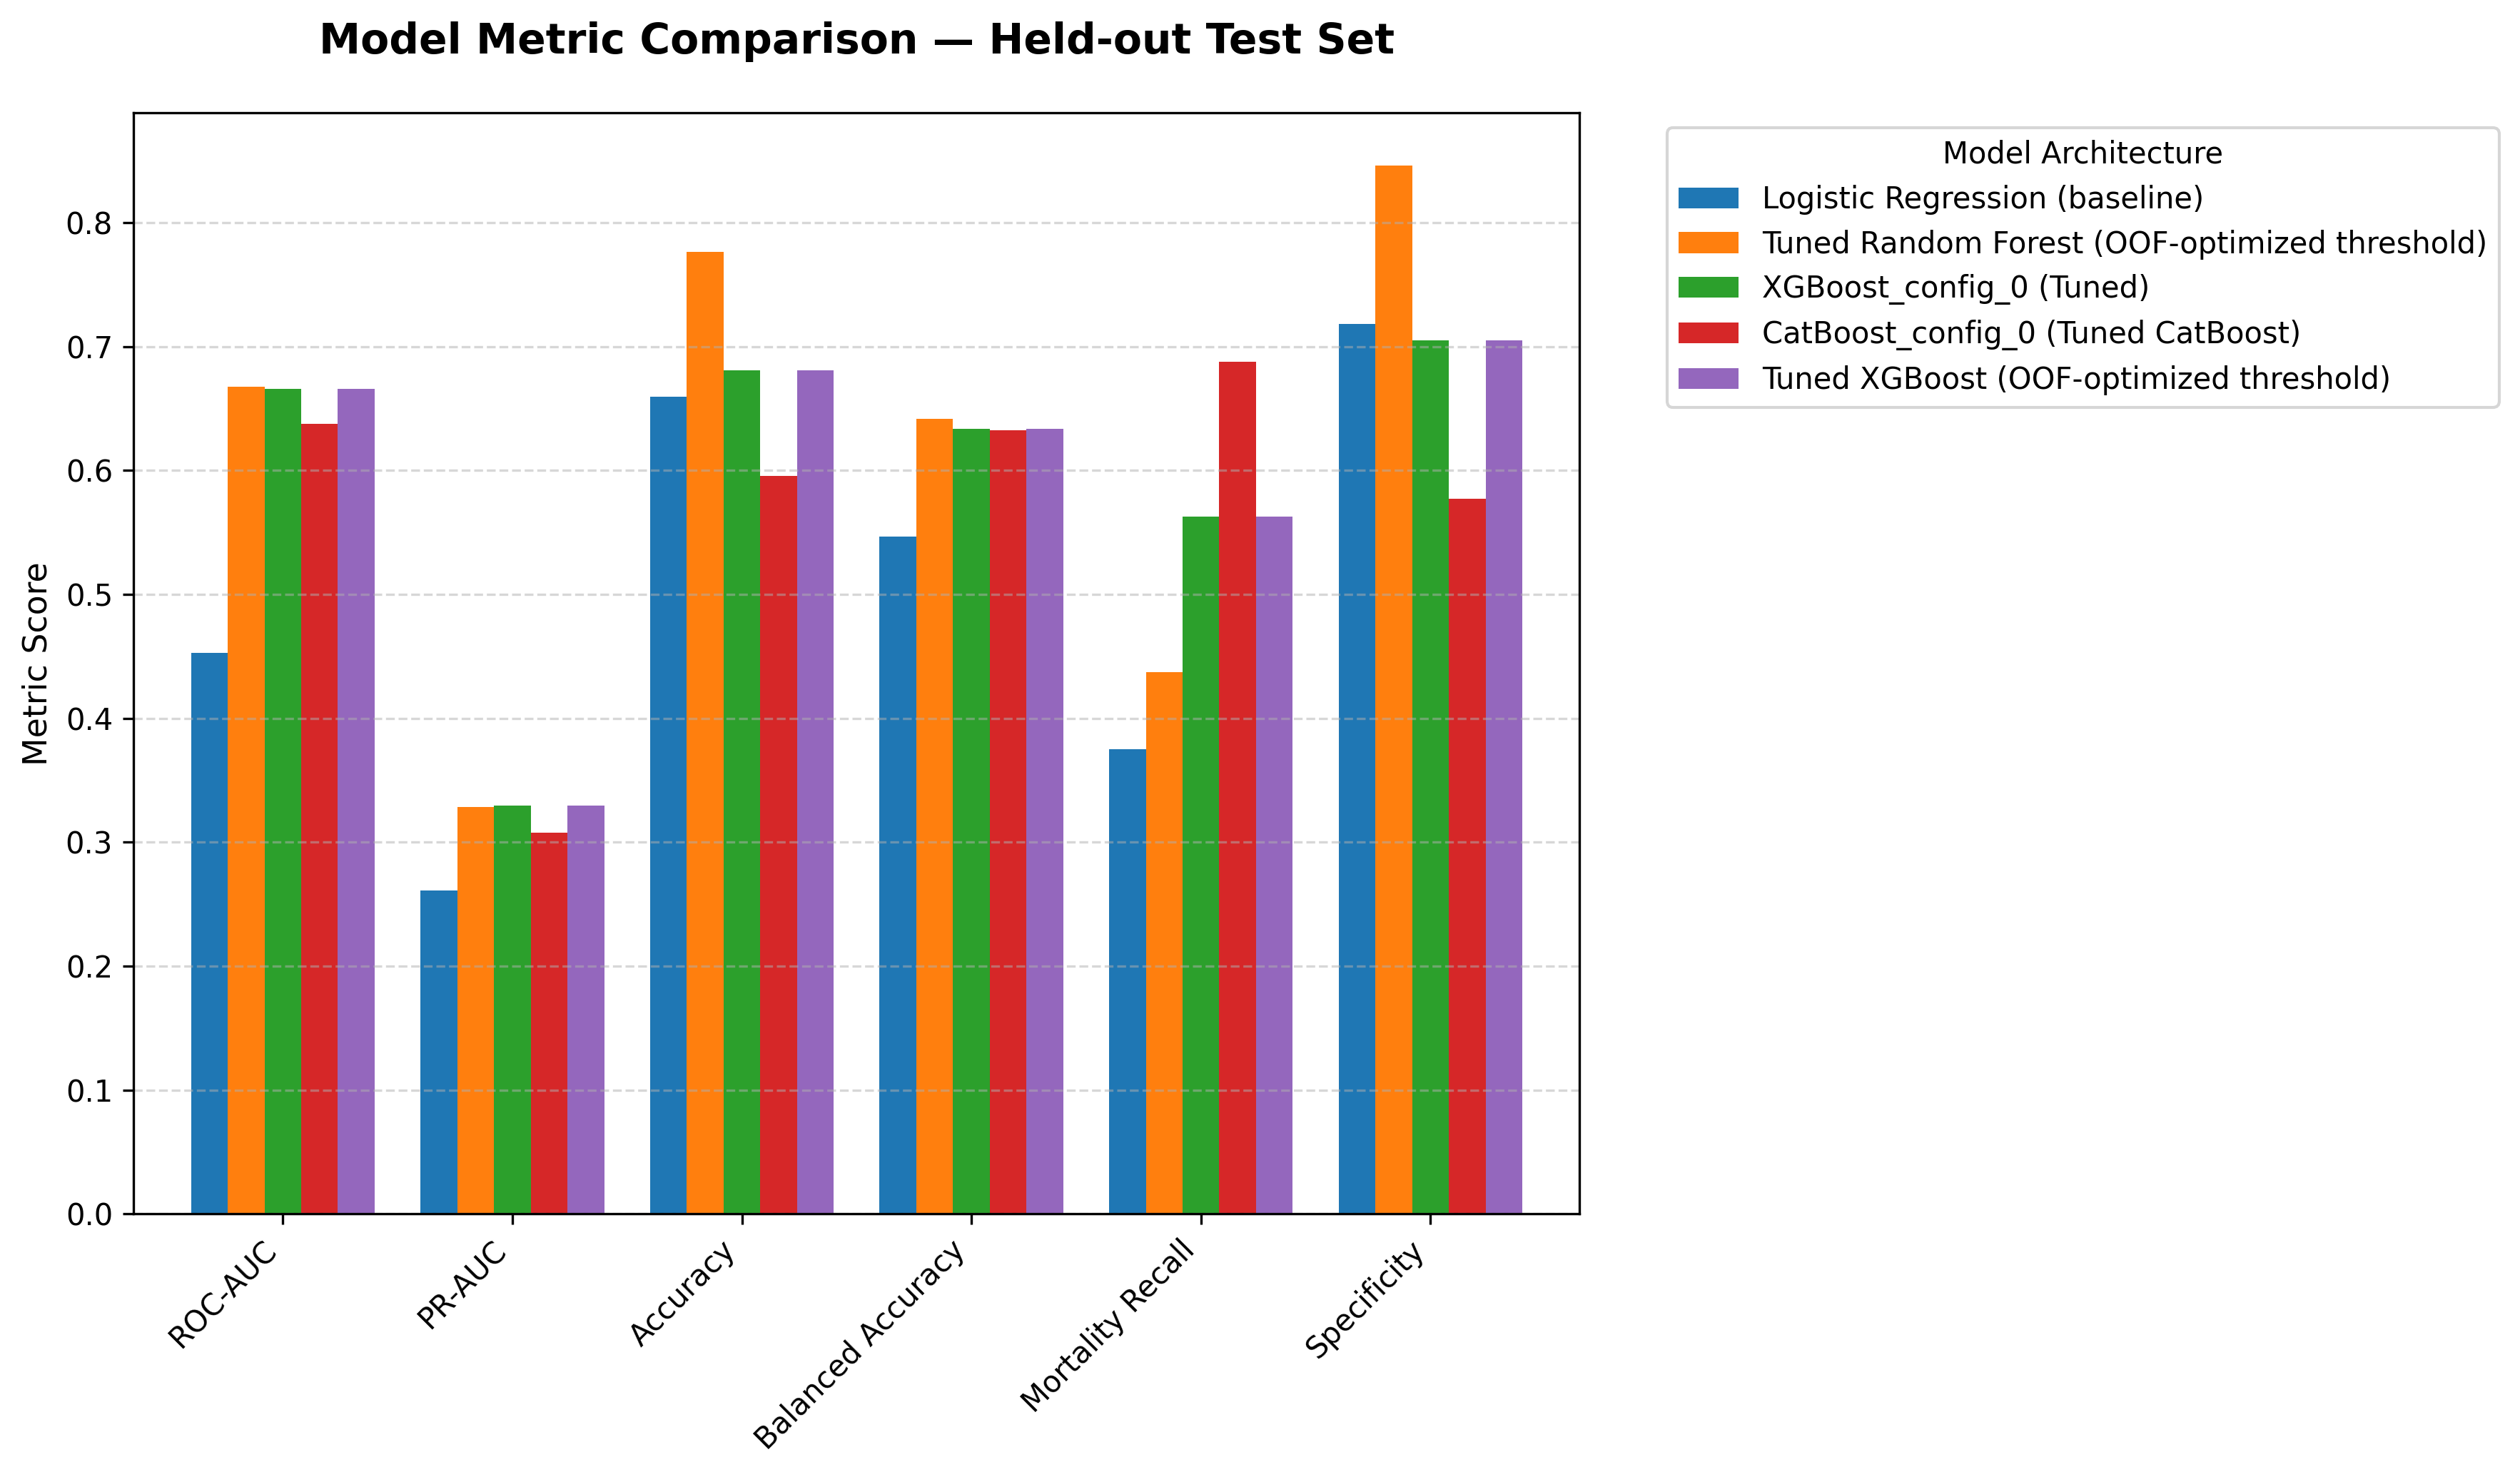

In [89]:
# 3. Bar Chart Model Comparison (PNG & PDF)
if 'final_benchmark_all' in globals():
    metrics_to_plot = ["ROC-AUC", "PR-AUC", "Accuracy", "Balanced Accuracy", "Mortality Recall", "Precision", "F1-Score", "Specificity"]
    available_metrics = [m for m in metrics_to_plot if m in final_benchmark_all.index]
    sub_df = final_benchmark_all.loc[available_metrics]

    fig, ax = plt.subplots(figsize=(12, 7), dpi=300)
    sub_df.plot(kind="bar", ax=ax, width=0.8)
    ax.set_ylabel("Metric Score", fontsize=11)
    ax.set_title("Model Metric Comparison — Held-out Test Set", fontsize=14, fontweight="bold", pad=20)
    ax.legend(title="Model Architecture", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
    plt.xticks(rotation=45, ha="right")
    plt.grid(True, axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "model_metrics_comparison.png", dpi=300, bbox_inches="tight")
    plt.savefig(FIG_DIR / "model_metrics_comparison.pdf", format="pdf", bbox_inches="tight")
    plt.show()
    plt.close()


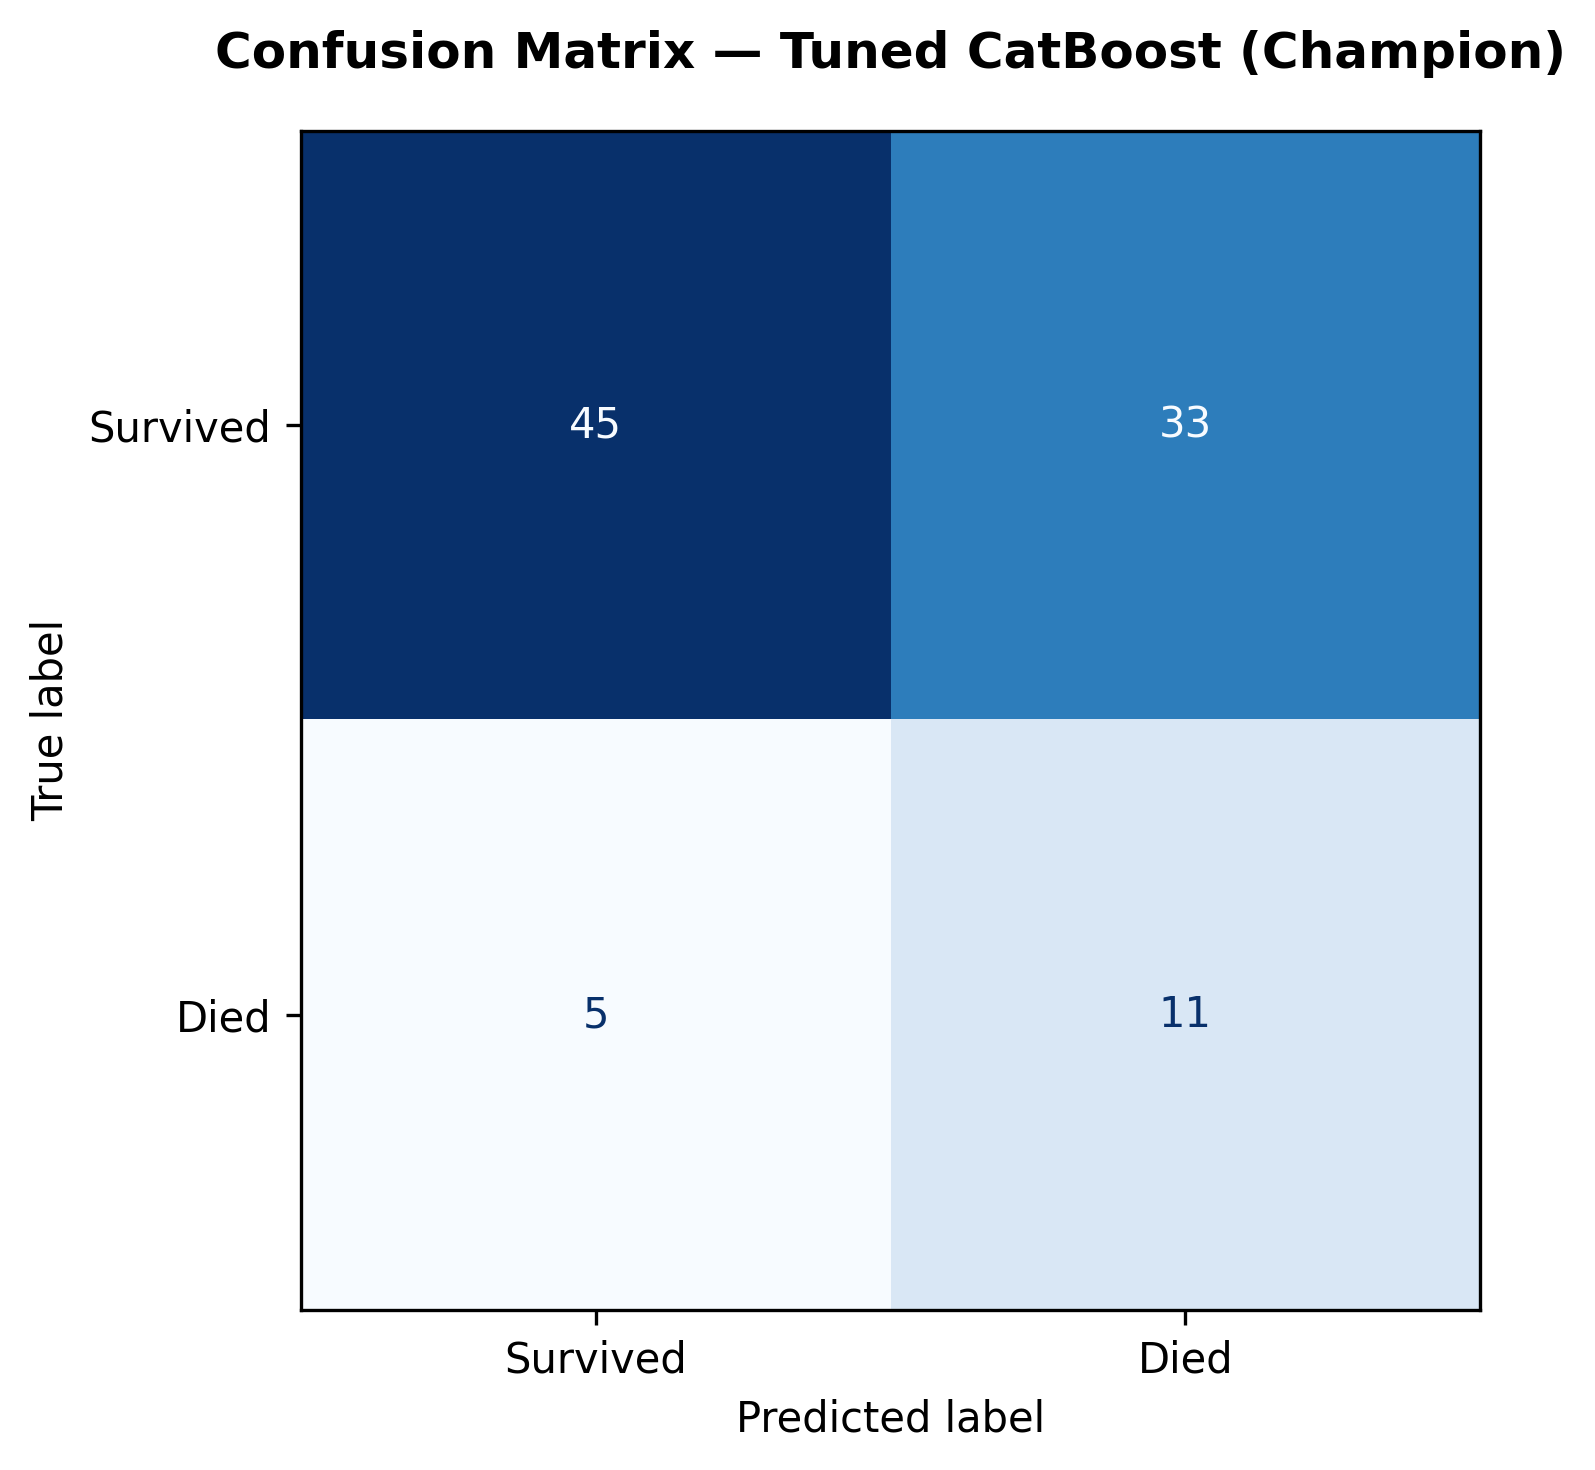

In [90]:
# 4. CatBoost Confusion Matrix (PNG & PDF)
if 'y_test' in globals() and 'cb_pred' in globals():
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    ConfusionMatrixDisplay.from_predictions(
        y_test, cb_pred, display_labels=["Survived", "Died"], ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion Matrix — Tuned CatBoost (Champion)", fontsize=12, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "catboost_confusion_matrix.png", dpi=300)
    plt.savefig(FIG_DIR / "catboost_confusion_matrix.pdf", format="pdf")
    plt.show()
    plt.close()


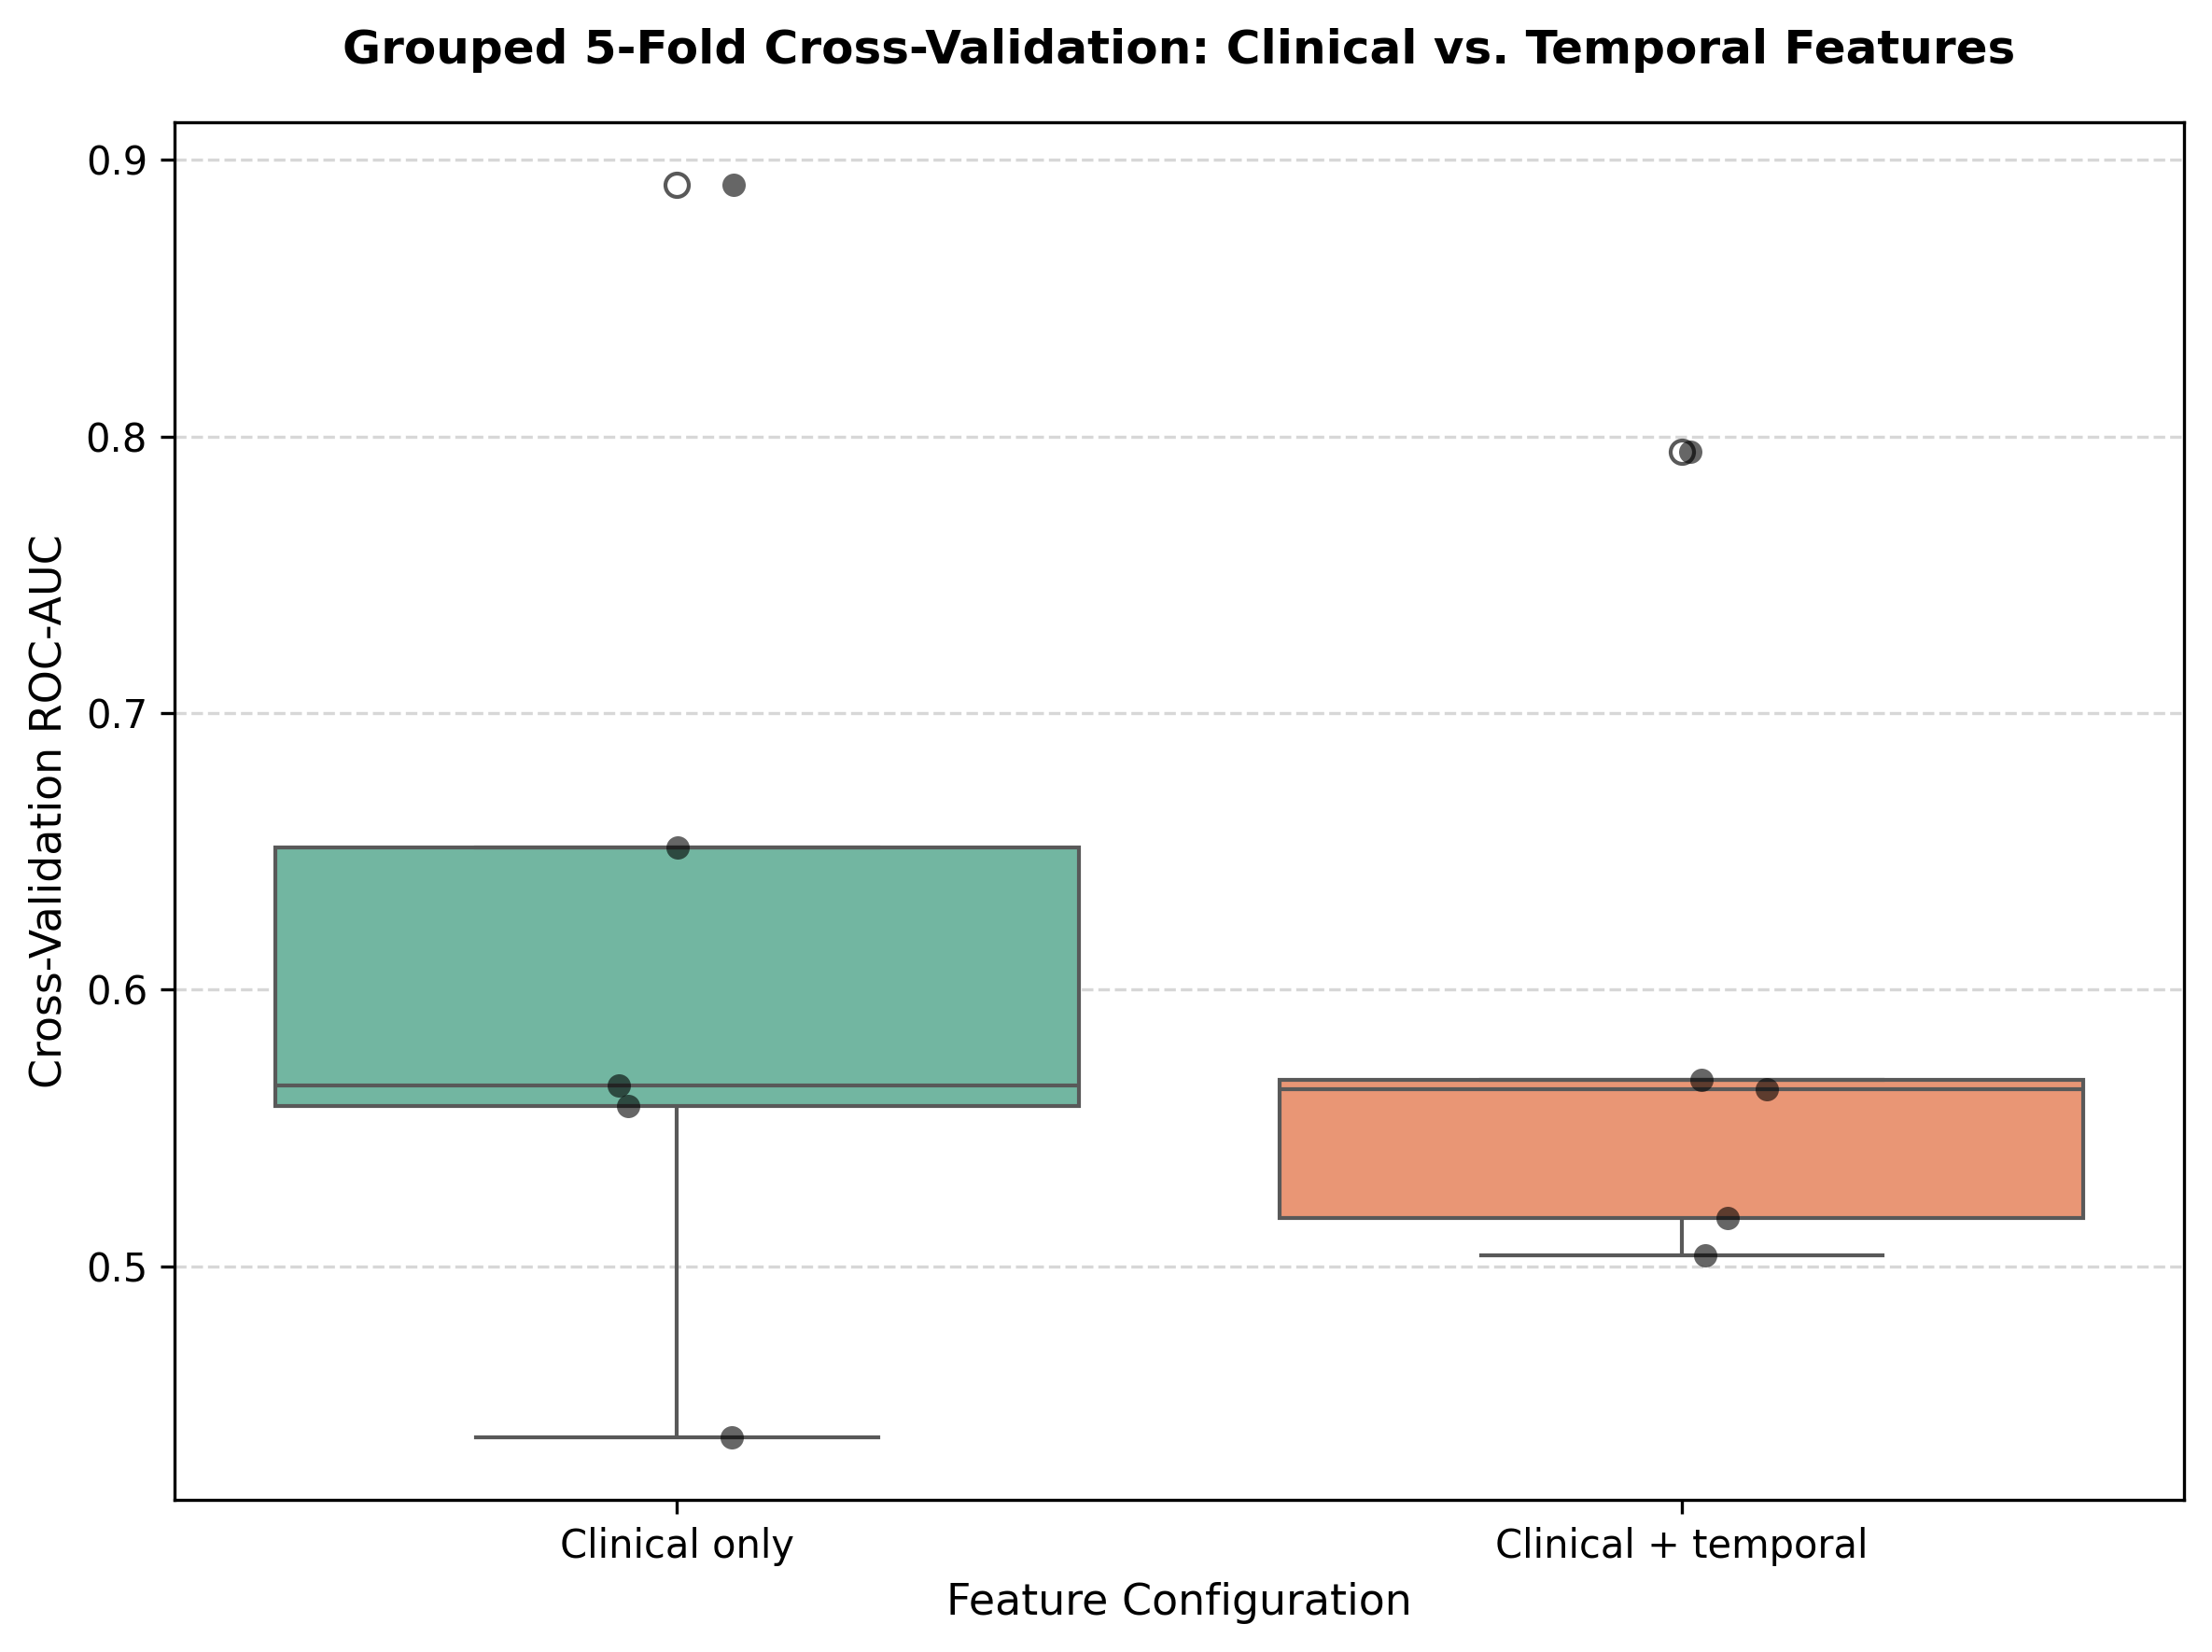

In [91]:
# 5. Clinical vs Clinical + Temporal (PNG & PDF)
if 'cv_results' in globals():
    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
    import seaborn as sns
    sns.boxplot(data=cv_results, x="feature_set", y="ROC_AUC", ax=ax, palette="Set2")
    sns.stripplot(data=cv_results, x="feature_set", y="ROC_AUC", ax=ax, color="black", alpha=0.6, size=6, jitter=0.1)
    ax.set_xlabel("Feature Configuration", fontsize=11)
    ax.set_ylabel("Cross-Validation ROC-AUC", fontsize=11)
    ax.set_title("Grouped 5-Fold Cross-Validation: Clinical vs. Temporal Features", fontsize=12, fontweight="bold", pad=15)
    plt.grid(True, axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "clinical_vs_temporal_cv_comparison.png", dpi=300)
    plt.savefig(FIG_DIR / "clinical_vs_temporal_cv_comparison.pdf", format="pdf")
    plt.show()
    plt.close()


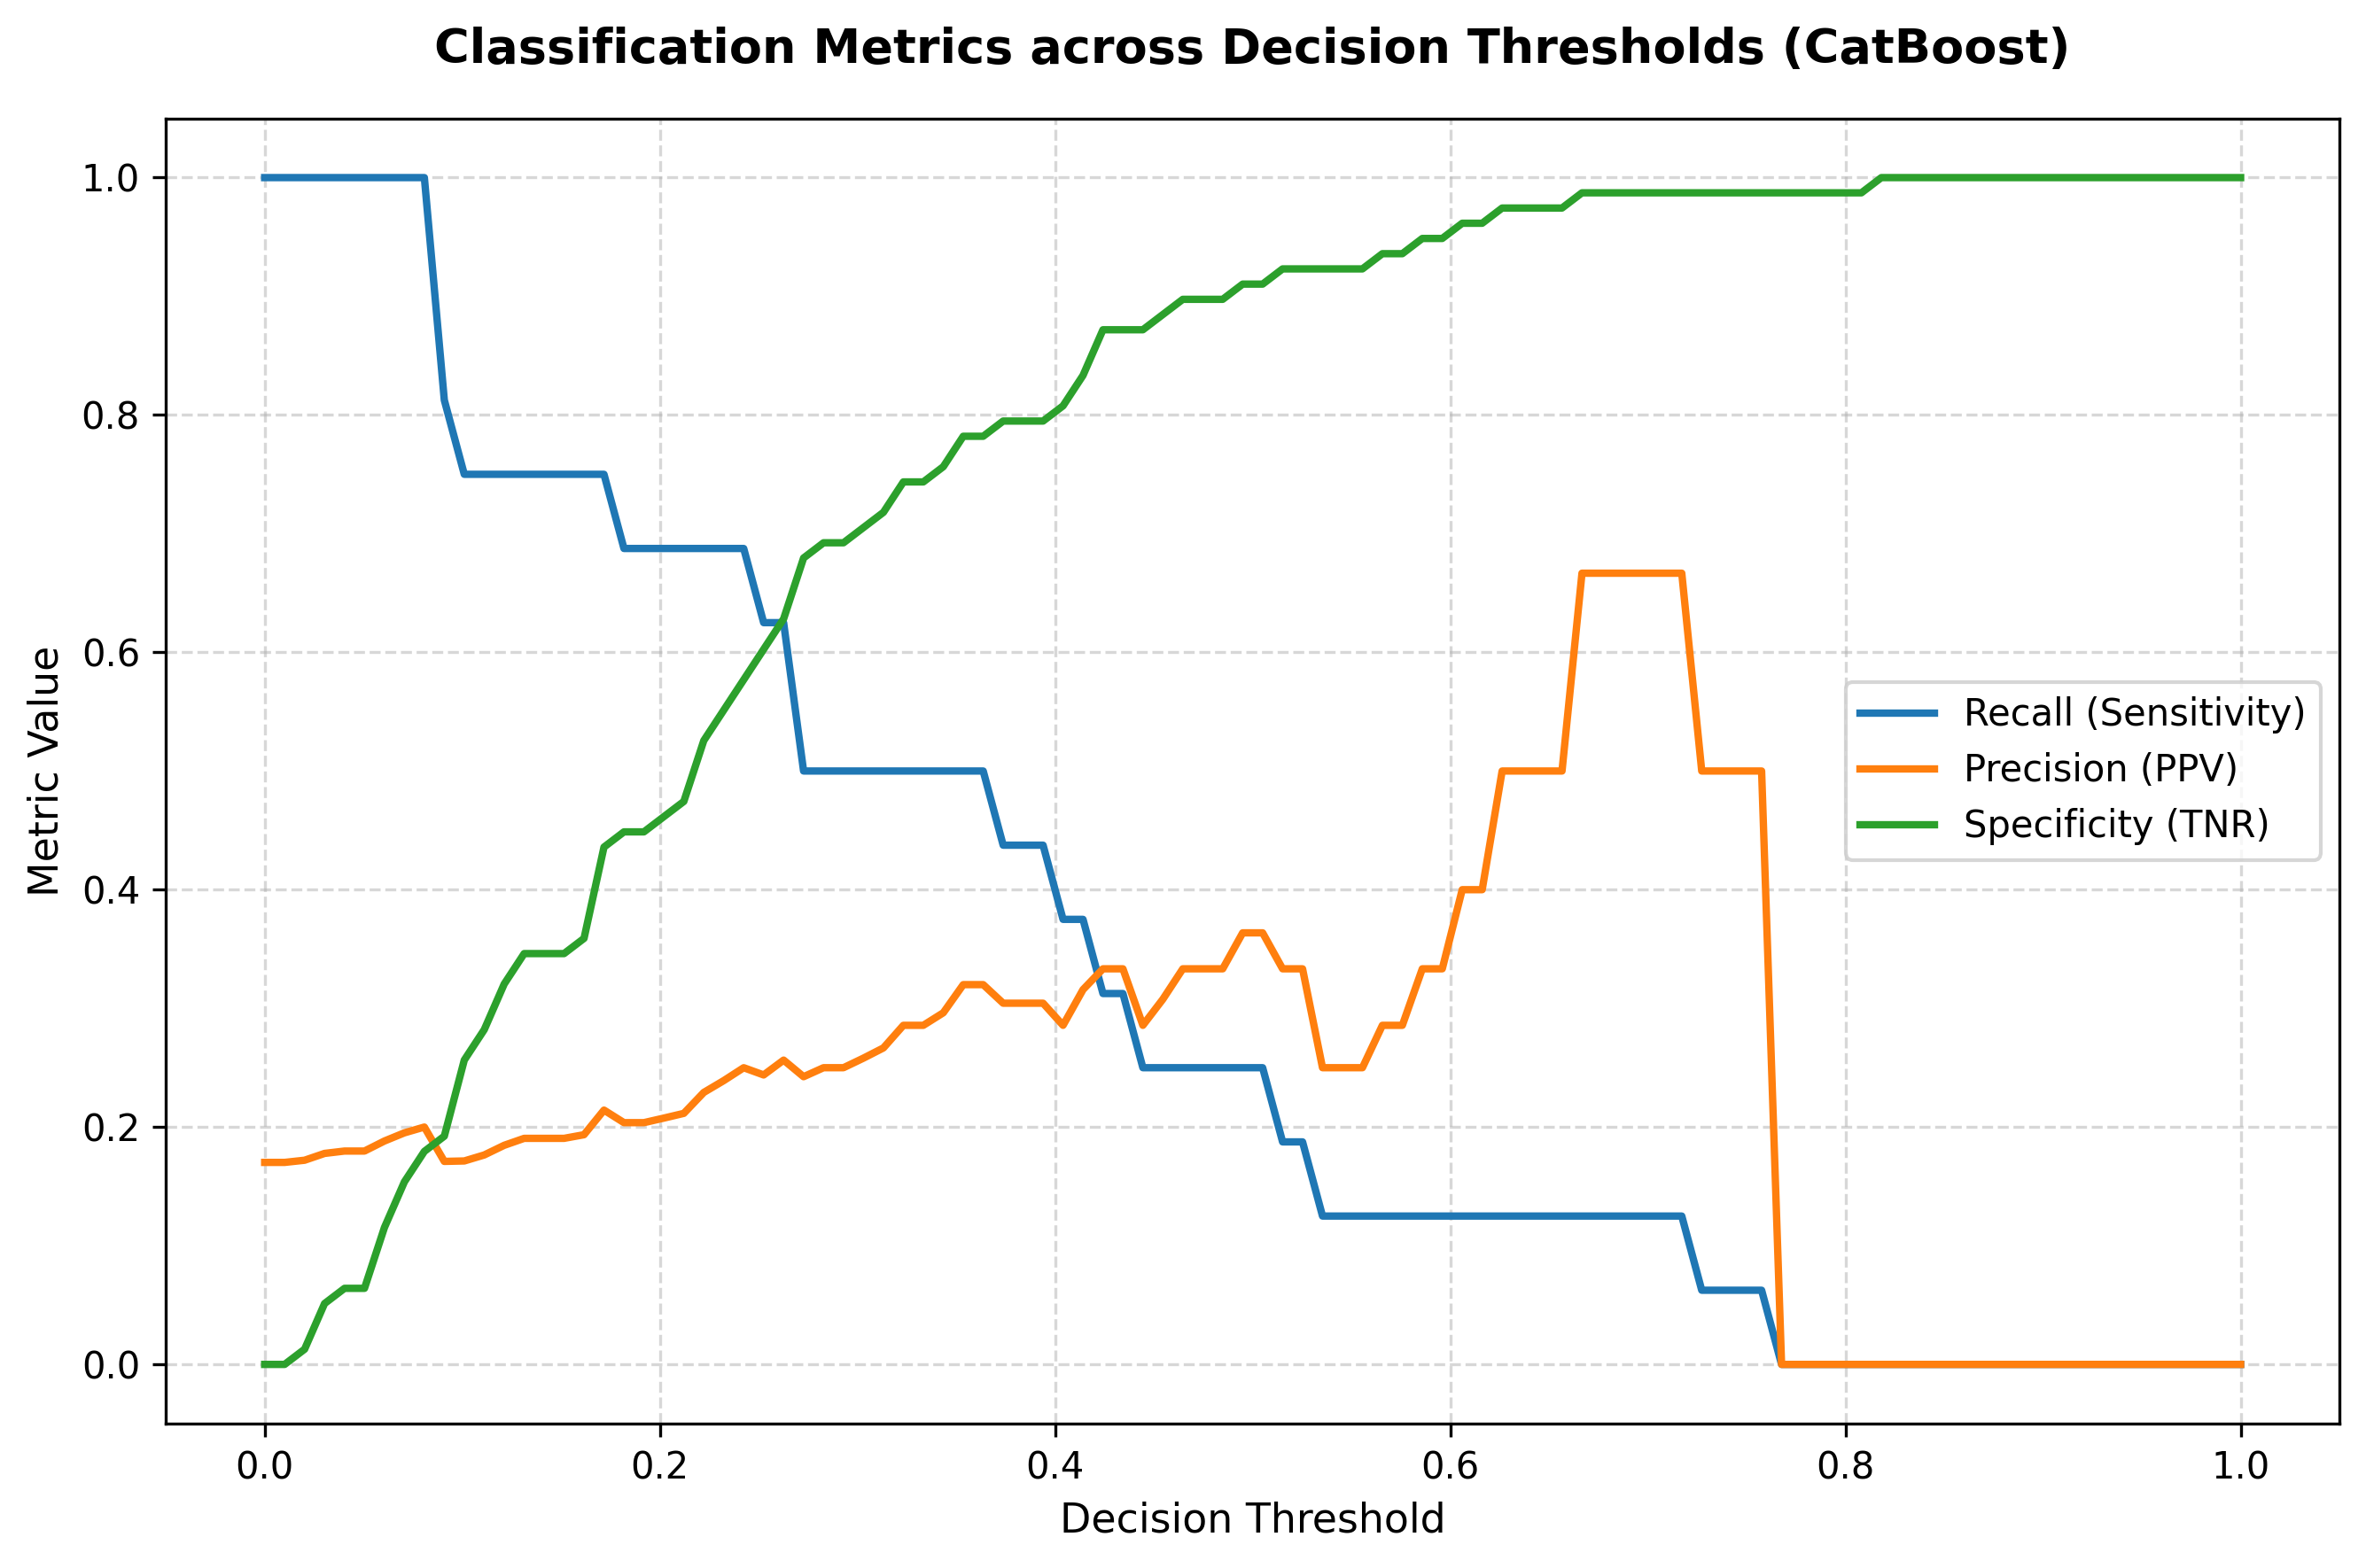

In [92]:
# 6. Threshold vs Recall/Precision/Specificity Curve (PNG & PDF)
if 'y_test' in globals() and 'cb_prob' in globals():
    thresholds = np.linspace(0, 1, 100)
    recalls = []
    precisions = []
    specificities = []

    for th in thresholds:
        preds = (cb_prob >= th).astype(int)
        recalls.append(recall_score(y_test, preds, zero_division=0))
        precisions.append(precision_score(y_test, preds, zero_division=0))
        tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
        specificities.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)

    plt.figure(figsize=(9, 6), dpi=300)
    plt.plot(thresholds, recalls, label="Recall (Sensitivity)", color="#1f77b4", lw=2)
    plt.plot(thresholds, precisions, label="Precision (PPV)", color="#ff7f0e", lw=2)
    plt.plot(thresholds, specificities, label="Specificity (TNR)", color="#2ca02c", lw=2)
    plt.xlabel("Decision Threshold", fontsize=11)
    plt.ylabel("Metric Value", fontsize=11)
    plt.title("Classification Metrics across Decision Thresholds (CatBoost)", fontsize=13, fontweight="bold", pad=15)
    plt.legend(loc="best", frameon=True)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "threshold_metrics_curve.png", dpi=300)
    plt.savefig(FIG_DIR / "threshold_metrics_curve.pdf", format="pdf")
    plt.show()
    plt.close()


In [93]:
# List all generated files inside research_figures/
print("Generated Figures in 'research_figures/':")
for f in sorted(FIG_DIR.glob("*")):
    print(f"- {f.name} ({f.stat().st_size:,} bytes)")


Generated Figures in 'research_figures/':
- catboost_confusion_matrix.pdf (22,303 bytes)
- catboost_confusion_matrix.png (64,248 bytes)
- clinical_vs_temporal_cv_comparison.pdf (23,745 bytes)
- clinical_vs_temporal_cv_comparison.png (108,706 bytes)
- model_metrics_comparison.pdf (27,573 bytes)
- model_metrics_comparison.png (263,283 bytes)
- test_set_pr_curves.pdf (26,710 bytes)
- test_set_pr_curves.png (274,585 bytes)
- test_set_roc_curves.pdf (25,007 bytes)
- test_set_roc_curves.png (229,206 bytes)
- threshold_metrics_curve.pdf (23,503 bytes)
- threshold_metrics_curve.png (212,621 bytes)
